<div style="background:#E6F2FF;text-align: center; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

# پروژه نهایی درس مبانی داده‌کاوی و کاربردهای آن
## پیش‌بینی وضعیت تأیید درخواست وام
### سونیا دباغ تفرشی - ۴۰۱۱۰۴۱۰۲
### پردیس رحیمی نصر - ۴۰۱۱۷۰۴۰۱
</div>


<div style="background:#D9E4DE;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
# ۱. آماده‌سازی محیط اجرا
</div>

In [1]:
import importlib.util
import subprocess
import sys

required_packages = {
    "shap": "shap",
    "imblearn": "imbalanced-learn",
    "openpyxl": "openpyxl",}

missing_packages = [
    pip_name
    for import_name, pip_name in required_packages.items()
    if importlib.util.find_spec(import_name) is None]

if missing_packages:
    print("نصب کتابخانه‌های موردنیاز:", ", ".join(missing_packages))
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet", *missing_packages])
else:
    print("همه کتابخانه‌های تکمیلی موردنیاز از قبل نصب هستند.")


نصب کتابخانه‌های موردنیاز: shap, imbalanced-learn


In [3]:
from pathlib import Path
import json
import platform
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler, FunctionTransformer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RepeatedStratifiedKFold,
    cross_validate,
    cross_val_predict,
    GridSearchCV,
    RandomizedSearchCV,
    learning_curve,)
from sklearn.metrics import (
    make_scorer,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.metrics import pairwise_distances
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE

warnings.filterwarnings("default")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)
with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message="IProgress not found.*",)
    import shap

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 3
N_JOBS = 2

np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

CV = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
SHAP_AVAILABLE = True

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.20,
    "axes.axisbelow": True,})

print("محیط اجرا و کتابخانه‌ها با موفقیت آماده شدند.")
print(f"نسخه SHAP: {shap.__version__}")

محیط اجرا و کتابخانه‌ها با موفقیت آماده شدند.
نسخه SHAP: 0.52.0


c:\Users\Sarir\AppData\Local\Programs\Python\Python313\Lib\site-packages\shap\plots\colors\_colors.py:47: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  red_blue.set_bad(gray_rgb.tolist(), 1.0)
c:\Users\Sarir\AppData\Local\Programs\Python\Python313\Lib\site-packages\shap\plots\colors\_colors.py:48: PendingDeprecationWarning: The set_over function will be deprecated in a future version. Use cmap.with_extremes(over=...) or Colormap(over=...) instead.
  red_blue.set_over(gray_rgb.tolist(), 1.0)
c:\Users\Sarir\AppData\Local\Programs\Python\Python313\Lib\site-packages\shap\plots\colors\_colors.py:49: PendingDeprecationWarning: The set_under function will be deprecated in a future version. Use cmap.with_extremes(under=...) or Colormap(under=...) instead.
  red_blue.set_under(gray_rgb.tolist(), 1.0)  # "under" is incorrectly used instead of "bad" in the scatter plot


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
## ۱-۱. یافتن و بارگذاری فایل‌ها
</div>


In [5]:
BASE_DIR = Path.cwd()

def find_data_file(candidates):
    search_dirs = [BASE_DIR, Path("/content"), Path("/mnt/data")]
    for directory in search_dirs:
        for name in candidates:
            path = directory / name
            if path.exists():
                return path
    raise FileNotFoundError(
        "هیچ‌یک از فایل‌های زیر پیدا نشدند:\n"
        + "\n".join(candidates)
        + f"\n\nپوشه اصلی بررسی‌شده: {BASE_DIR}")

TRAIN_PATH = find_data_file(["loan_train.csv", "loan_train(1).csv"])
TEST_PATH = find_data_file(["loan_test.csv", "loan_test(1).csv"])

train_raw = pd.read_csv(TRAIN_PATH)
test_raw = pd.read_csv(TEST_PATH)

OUTPUT_DIR = BASE_DIR / "outputs_complete"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"پوشه اجرای نوت‌بوک: {BASE_DIR}")
print(f"مسیر داده آموزش: {TRAIN_PATH}")
print(f"مسیر داده آزمون: {TEST_PATH}")
print(f"پوشه خروجی‌ها: {OUTPUT_DIR.resolve()}")
print(f"ابعاد آموزش: {train_raw.shape}")
print(f"ابعاد آزمون: {test_raw.shape}")

پوشه اجرای نوت‌بوک: c:\Users\Sarir\Downloads
مسیر داده آموزش: c:\Users\Sarir\Downloads\loan_train.csv
مسیر داده آزمون: c:\Users\Sarir\Downloads\loan_test.csv
پوشه خروجی‌ها: C:\Users\Sarir\Downloads\outputs_complete
ابعاد آموزش: (614, 12)
ابعاد آزمون: (367, 11)


<div style="background:#D9E4DE;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
# ۲. درک و شناخت داده
</div>


<div style="text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۲-۱. شناخت نوع داده

| ستون | نوع مفهومی | توضیح |
|---|---|---|
| `Gender` | دسته‌ای دودویی | جنسیت متقاضی |
| `Married` | دسته‌ای دودویی | وضعیت تأهل |
| `Dependents` | دسته‌ای ترتیبی | تعداد افراد تحت تکفل |
| `Education` | دسته‌ای دودویی | وضعیت تحصیلات |
| `Self_Employed` | دسته‌ای دودویی | خوداشتغالی |
| `Applicant_Income` | عددی پیوسته | درآمد متقاضی |
| `Coapplicant_Income` | عددی پیوسته | درآمد متقاضی مشترک |
| `Loan_Amount` | عددی پیوسته | مبلغ وام درخواستی |
| `Term` | عددی گسسته | مدت بازپرداخت |
| `Credit_History` | دودویی | سابقه اعتباری |
| `Area` | دسته‌ای اسمی | نوع منطقه سکونت |
| `Status` | متغیر هدف | تأیید (`Y`) یا رد (`N`) درخواست |
</div>


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
## ۲-۲. نمایش نمونه‌ها، نوع ستون‌ها و ساختار
</div>


In [6]:
TARGET = "Status"

expected_features = [
    "Gender", "Married", "Dependents", "Education", "Self_Employed",
    "Applicant_Income", "Coapplicant_Income", "Loan_Amount", "Term",
    "Credit_History", "Area"]

missing_train_columns = sorted(set(expected_features + [TARGET]) - set(train_raw.columns))
missing_test_columns = sorted(set(expected_features) - set(test_raw.columns))

unexpected_test_target = TARGET in test_raw.columns
invalid_target_values = sorted(
    set(train_raw[TARGET].dropna().unique()) - {"Y", "N"}
) if TARGET in train_raw.columns else []

if missing_train_columns:
    raise ValueError(f"ستون‌های ضروری داده آموزش موجود نیستند: {missing_train_columns}")
if missing_test_columns:
    raise ValueError(f"ستون‌های ضروری داده آزمون موجود نیستند: {missing_test_columns}")
if unexpected_test_target:
    raise ValueError("فایل آزمون نهایی نباید دارای ستون هدف Status باشد.")
if invalid_target_values:
    raise ValueError(f"مقادیر نامعتبر در ستون هدف مشاهده شد: {invalid_target_values}")

print("نمونه داده آموزش:")
display(train_raw.head())

print("نمونه داده آزمون:")
display(test_raw.head())

schema_table = pd.DataFrame({
    "Train dtype": train_raw.dtypes.astype(str),
    "Train non-null": train_raw.notna().sum(),
    "Test dtype": test_raw.dtypes.reindex(train_raw.columns).astype(str),
    "Test non-null": test_raw.notna().sum().reindex(train_raw.columns),})

display(schema_table)

نمونه داده آموزش:


,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Term,Credit_History,Area,Status
0,Male,No,0,Graduate,No,584900,0.0000,15000000,360.0000,1.0000,Urban,Y
1,Male,Yes,1,Graduate,No,458300,"150,800.0000",12800000,360.0000,1.0000,Rural,N
2,Male,Yes,0,Graduate,Yes,300000,0.0000,6600000,360.0000,1.0000,Urban,Y
3,Male,Yes,0,Not Graduate,No,258300,"235,800.0000",12000000,360.0000,1.0000,Urban,Y
4,Male,No,0,Graduate,No,600000,0.0000,14100000,360.0000,1.0000,Urban,Y


نمونه داده آزمون:


,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Term,Credit_History,Area
0,Male,Yes,0,Graduate,No,572000,0,11000000,360.0000,1.0000,Urban
1,Male,Yes,1,Graduate,No,307600,150000,12600000,360.0000,1.0000,Urban
2,Male,Yes,2,Graduate,No,500000,180000,20800000,360.0000,1.0000,Urban
3,Male,Yes,2,Graduate,No,234000,254600,10000000,360.0000,NaN,Urban
4,Male,No,0,Not Graduate,No,327600,0,7800000,360.0000,1.0000,Urban


,Train dtype,Train non-null,Test dtype,Test non-null
Gender,object,601,object,356.0000
Married,object,611,object,367.0000
Dependents,object,599,object,357.0000
Education,object,614,object,367.0000
Self_Employed,object,582,object,344.0000
Applicant_Income,int64,614,int64,367.0000
Coapplicant_Income,float64,614,int64,367.0000
Loan_Amount,int64,614,int64,367.0000
Term,float64,600,float64,361.0000
Credit_History,float64,564,float64,338.0000


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
## ۲-۳. کنترل ردیف‌های تکراری و مقادیر نامعتبر
</div>


In [7]:
def data_quality_audit(df, dataset_name):
    report = {
        "Dataset": dataset_name,
        "Rows": len(df),
        "Columns": df.shape[1],
        "Duplicate rows": int(df.duplicated().sum()),
        "Nonpositive Loan_Amount": int((pd.to_numeric(df["Loan_Amount"], errors="coerce") <= 0).sum()),
        "Nonpositive Term": int((pd.to_numeric(df["Term"], errors="coerce") <= 0).sum()),
        "Negative Applicant_Income": int((pd.to_numeric(df["Applicant_Income"], errors="coerce") < 0).sum()),
        "Negative Coapplicant_Income": int((pd.to_numeric(df["Coapplicant_Income"], errors="coerce") < 0).sum()),}
    return report

audit_table = pd.DataFrame([
    data_quality_audit(train_raw, "Train"),
    data_quality_audit(test_raw, "Test"),])
display(audit_table)


def apply_domain_cleaning(df):
    cleaned = df.copy()
    for col in ["Loan_Amount", "Term"]:
        cleaned.loc[pd.to_numeric(cleaned[col], errors="coerce") <= 0, col] = np.nan
    for col in ["Applicant_Income", "Coapplicant_Income"]:
        cleaned.loc[pd.to_numeric(cleaned[col], errors="coerce") < 0, col] = np.nan
    return cleaned

train = apply_domain_cleaning(train_raw)
test = apply_domain_cleaning(test_raw)

print("تعداد مقادیر گمشده پس از اعمال قواعد دامنه:")
display(pd.DataFrame({
    "Train missing": train.isna().sum(),
    "Test missing": test.isna().sum().reindex(train.columns),}))

,Dataset,Rows,Columns,Duplicate rows,Nonpositive Loan_Amount,Nonpositive Term,Negative Applicant_Income,Negative Coapplicant_Income
0,Train,614,12,0,21,0,0,0
1,Test,367,11,1,5,0,0,0


تعداد مقادیر گمشده پس از اعمال قواعد دامنه:


,Train missing,Test missing
Gender,13,11.0000
Married,3,0.0000
Dependents,15,10.0000
Education,0,0.0000
Self_Employed,32,23.0000
Applicant_Income,0,0.0000
Coapplicant_Income,0,0.0000
Loan_Amount,21,5.0000
Term,14,6.0000
Credit_History,50,29.0000


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
## ۲-۴. آمار توصیفی متغیرهای عددی
</div>


In [8]:
numeric_original = [
    "Applicant_Income", "Coapplicant_Income", "Loan_Amount", "Term", "Credit_History"]

numeric_summary = train[numeric_original].describe(percentiles=[0.25, 0.5, 0.75]).T
numeric_summary["median"] = train[numeric_original].median()
numeric_summary["skewness"] = train[numeric_original].skew(numeric_only=True)
numeric_summary["n_unique"] = train[numeric_original].nunique(dropna=True)
numeric_summary["missing_pct"] = train[numeric_original].isna().mean() * 100

display(numeric_summary[[
    "count", "mean", "median", "std", "min", "25%", "50%", "75%", "max",
    "skewness", "n_unique", "missing_pct"]])

,count,mean,median,std,min,25%,50%,75%,max,skewness,n_unique,missing_pct
Applicant_Income,614.0000,"540,345.9283","381,250.0000","610,904.1673","15,000.0000","287,750.0000","381,250.0000","579,500.0000","8,100,000.0000",6.5395,505,0.0000
Coapplicant_Income,614.0000,"162,124.5798","118,850.0000","292,624.8369",0.0000,0.0000,"118,850.0000","229,725.0000","4,166,700.0000",7.4915,287,0.0000
Loan_Amount,593.0000,"14,641,821.2479","12,800,000.0000","8,551,513.5014","900,000.0000","10,000,000.0000","12,800,000.0000","16,800,000.0000","70,000,000.0000",2.6796,203,3.4202
Term,600.0000,342.0000,360.0000,65.1204,12.0000,360.0000,360.0000,360.0000,480.0000,-2.3624,10,2.2801
Credit_History,564.0000,0.8422,1.0000,0.3649,0.0000,1.0000,1.0000,1.0000,1.0000,-1.8824,2,8.1433


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
## ۲-۵. خلاصه متغیرهای دسته‌ای
</div>


In [9]:
categorical_original = [
    "Gender", "Married", "Dependents", "Education", "Self_Employed", "Area"]

categorical_rows = []
for col in categorical_original + [TARGET]:
    counts = train[col].value_counts(dropna=False)
    categorical_rows.append({
        "Feature": col,
        "Unique non-null": train[col].nunique(dropna=True),
        "Missing": int(train[col].isna().sum()),
        "Most frequent": counts.index[0],
        "Most frequent count": int(counts.iloc[0]),
        "Most frequent pct": float(counts.iloc[0] / len(train) * 100),})

display(pd.DataFrame(categorical_rows))

for col in categorical_original + [TARGET]:
    print(f"\nفراوانی {col}:")
    display(train[col].value_counts(dropna=False).to_frame("Count"))

,Feature,Unique non-null,Missing,Most frequent,Most frequent count,Most frequent pct
0,Gender,2,13,Male,489,79.6417
1,Married,2,3,Yes,398,64.8208
2,Dependents,4,15,0,345,56.1889
3,Education,2,0,Graduate,480,78.1759
4,Self_Employed,2,32,No,500,81.4332
5,Area,3,0,Semiurban,233,37.9479
6,Status,2,0,Y,422,68.7296



فراوانی Gender:


,Count
Gender,
Male,489
Female,112
NaN,13



فراوانی Married:


,Count
Married,
Yes,398
No,213
NaN,3


...

,Count
Self_Employed,
No,500
Yes,82
NaN,32



فراوانی Area:


,Count
Area,
Semiurban,233
Urban,202
Rural,179



فراوانی Status:


,Count
Status,
Y,422
N,192


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
## ۲-۶. بررسی مقادیر گمشده
</div>


,Missing count,Missing percent
Credit_History,50,8.1433
Self_Employed,32,5.2117
Loan_Amount,21,3.4202
Dependents,15,2.4430
Term,14,2.2801
Gender,13,2.1173
Married,3,0.4886
Education,0,0.0000
Coapplicant_Income,0,0.0000
Applicant_Income,0,0.0000


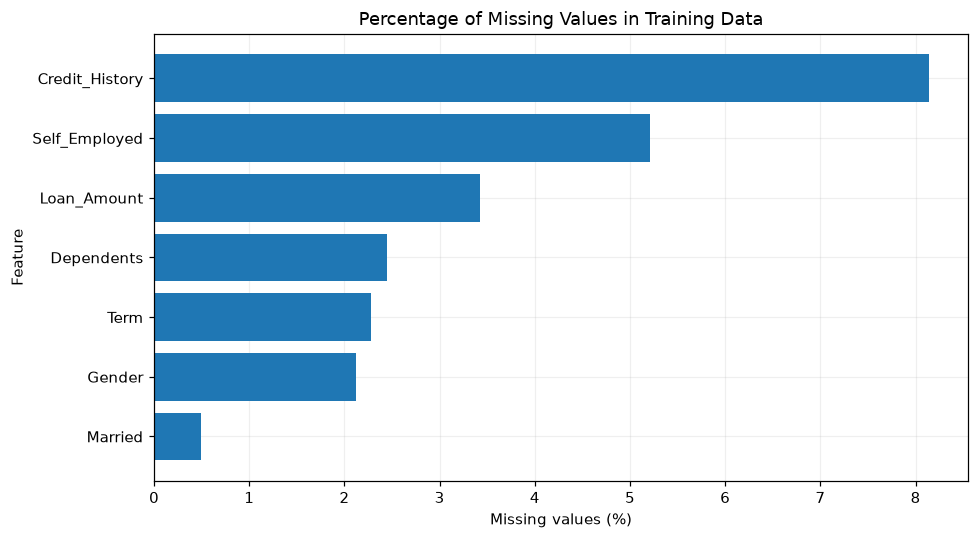

In [10]:
missing_table = pd.DataFrame({
    "Missing count": train.isna().sum(),
    "Missing percent": train.isna().mean() * 100,
}).sort_values("Missing percent", ascending=False)

display(missing_table)

plot_data = missing_table[missing_table["Missing count"] > 0].sort_values("Missing percent")
plt.figure(figsize=(9, 5))
plt.barh(plot_data.index, plot_data["Missing percent"])
plt.xlabel("Missing values (%)")
plt.ylabel("Feature")
plt.title("Percentage of Missing Values in Training Data")
plt.tight_layout()
plt.show()

<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
## ۲-۷. بررسی تعادل متغیر هدف
</div>


,Count,Percent
Status,,
Y,422,68.7296
N,192,31.2704


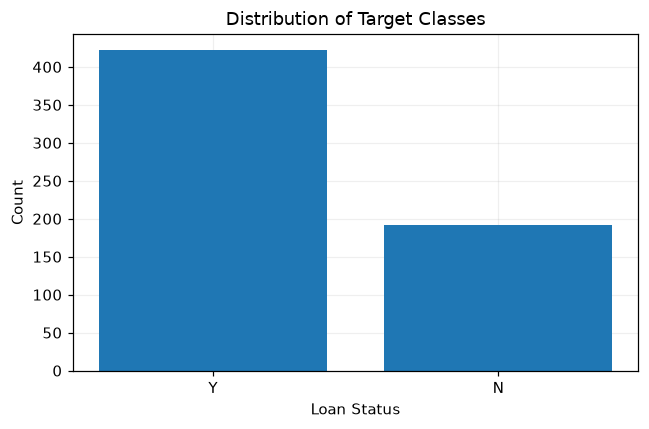

Accuracy: 0.6873


In [11]:
target_counts = train[TARGET].value_counts().rename("Count").to_frame()
target_counts["Percent"] = target_counts["Count"] / len(train) * 100
display(target_counts)

plt.figure(figsize=(6, 4))
plt.bar(target_counts.index.astype(str), target_counts["Count"])
plt.xlabel("Loan Status")
plt.ylabel("Count")
plt.title("Distribution of Target Classes")
plt.tight_layout()
plt.show()

majority_baseline = target_counts["Count"].max() / target_counts["Count"].sum()
print(f"Accuracy: {majority_baseline:.4f}")

<div style="background:#D9E4DE;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
# ۳. تحلیل اکتشافی داده‌ها
</div>


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
## ۳-۱. نرخ تأیید وام در گروه‌های مختلف
</div>



نرخ تأیید برحسب Gender:


,count,approval_percent
Gender,,
Male,489,69.3252
Female,112,66.9643
Missing,13,61.5385


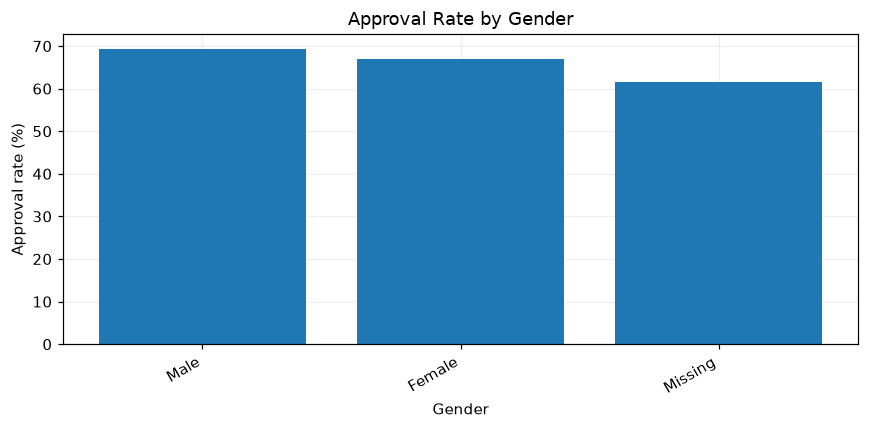


نرخ تأیید برحسب Married:


,count,approval_percent
Married,,
Missing,3,100.0000
Yes,398,71.6080
No,213,62.9108


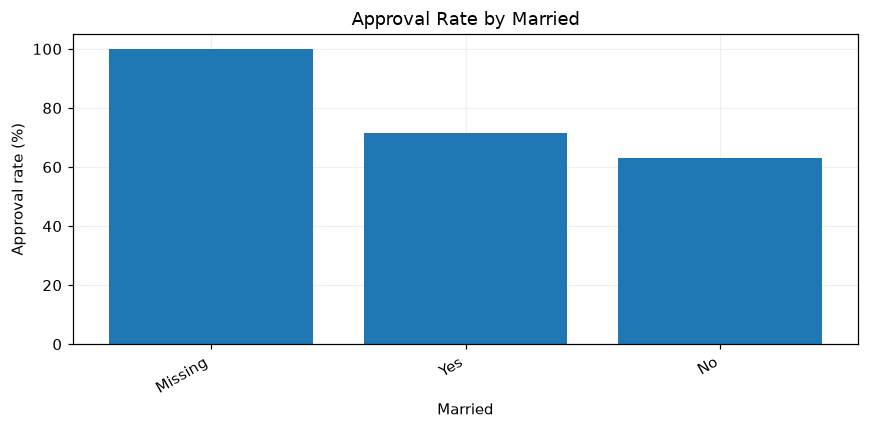


نرخ تأیید برحسب Dependents:


,count,approval_percent
Dependents,,
2,101,75.2475
0,345,68.9855
1,102,64.7059
3+,51,64.7059
Missing,15,60.0000


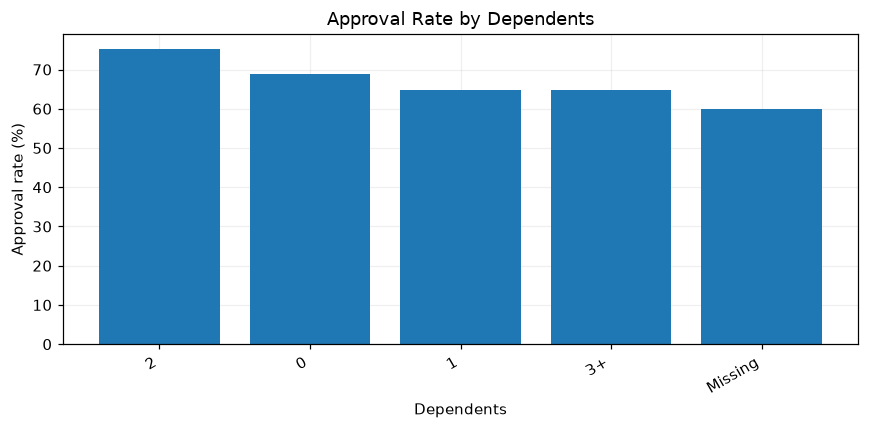


نرخ تأیید برحسب Education:


,count,approval_percent
Education,,
Graduate,480,70.8333
Not Graduate,134,61.1940


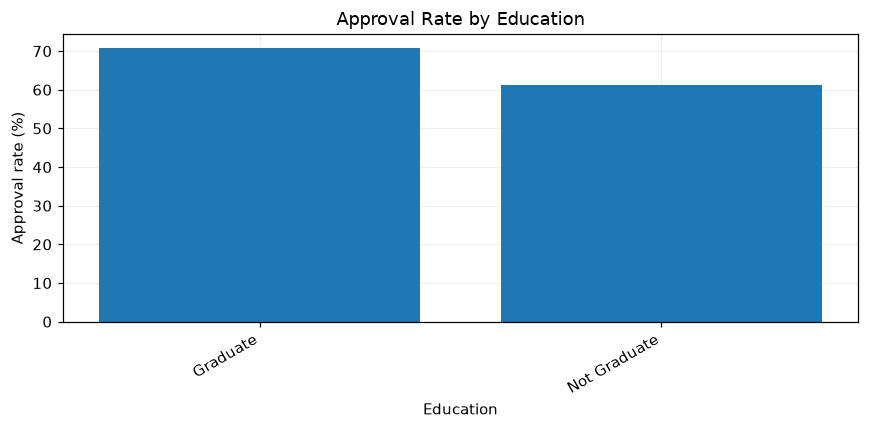


نرخ تأیید برحسب Self_Employed:


,count,approval_percent
Self_Employed,,
Missing,32,71.8750
No,500,68.6000
Yes,82,68.2927


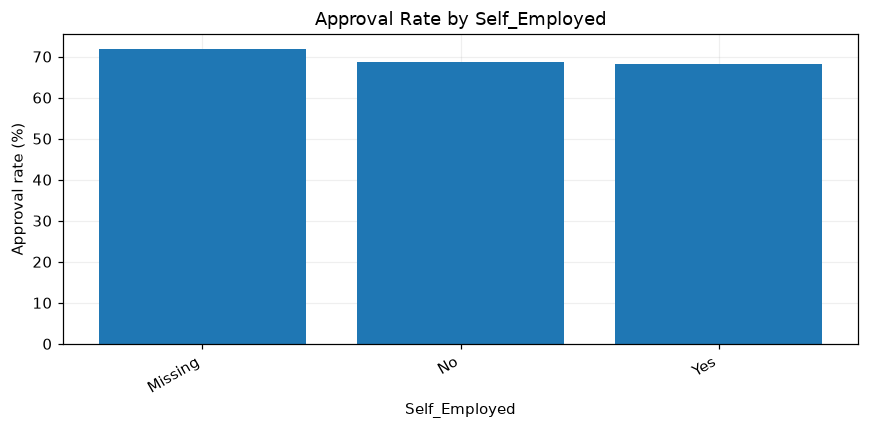


نرخ تأیید برحسب Area:


,count,approval_percent
Area,,
Semiurban,233,76.8240
Urban,202,65.8416
Rural,179,61.4525


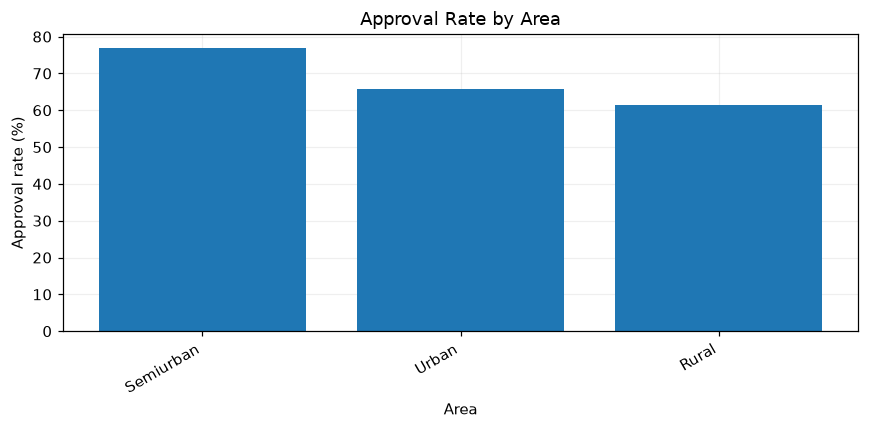


نرخ تأیید برحسب Credit_History:


,count,approval_percent
Credit_History,,
1.0000,475,79.5789
Missing,50,74.0000
0.0000,89,7.8652


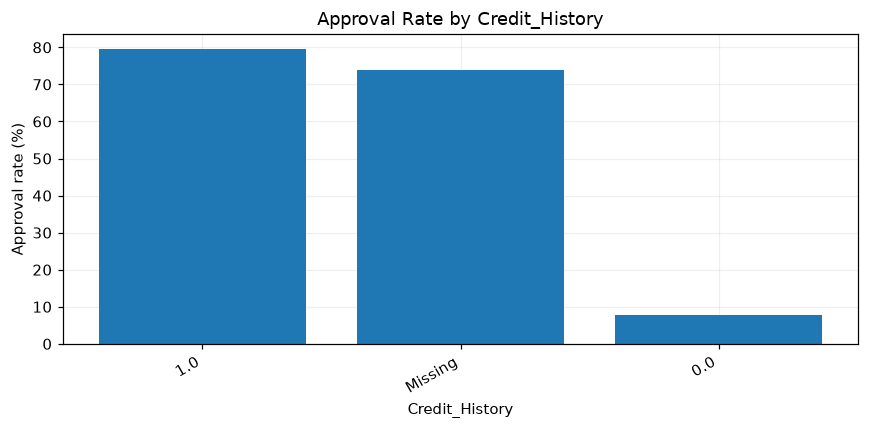

In [12]:
eda_target = train[TARGET].map({"N": 0, "Y": 1})

approval_tables = {}
for col in categorical_original + ["Credit_History"]:
    temp = pd.DataFrame({col: train[col].fillna("Missing"), "Approved": eda_target})
    table = temp.groupby(col, dropna=False)["Approved"].agg(["count", "mean"]).sort_values("mean", ascending=False)
    table["approval_percent"] = table["mean"] * 100
    approval_tables[col] = table
    print(f"\nنرخ تأیید برحسب {col}:")
    display(table[["count", "approval_percent"]])

    plt.figure(figsize=(8, 4))
    plt.bar(table.index.astype(str), table["approval_percent"])
    plt.xlabel(col)
    plt.ylabel("Approval rate (%)")
    plt.title(f"Approval Rate by {col}")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
## ۳-۲. توزیع متغیرهای عددی
</div>


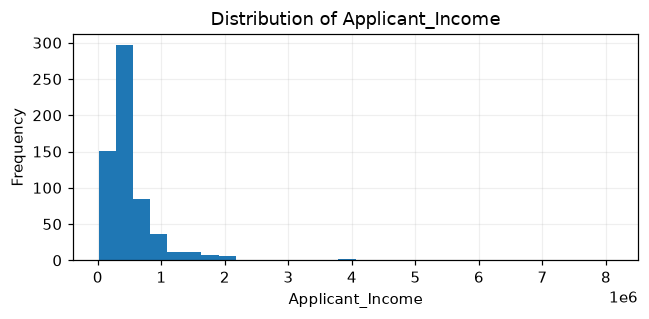

چولگی Applicant_Income: 6.5395


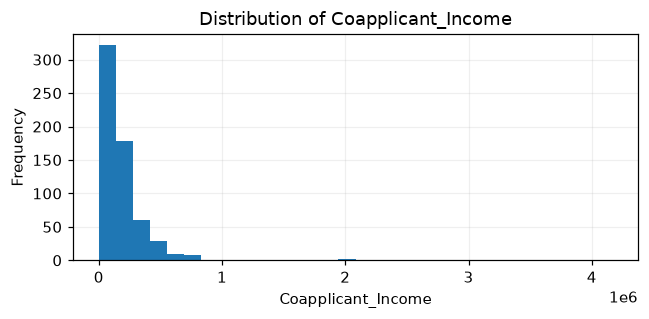

چولگی Coapplicant_Income: 7.4915


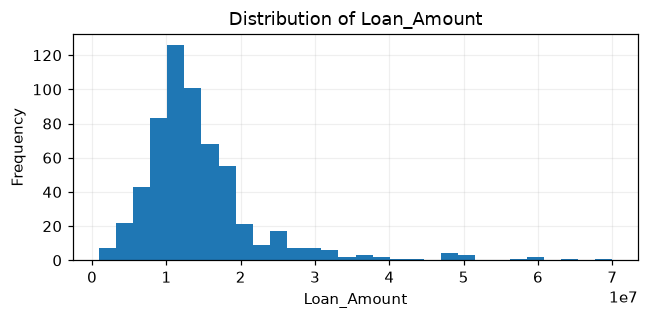

چولگی Loan_Amount: 2.6796


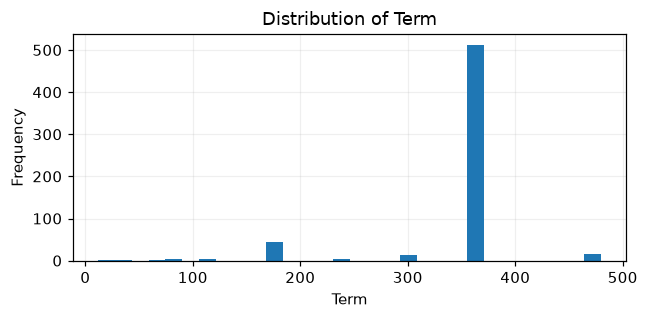

چولگی Term: -2.3624


In [13]:
for col in ["Applicant_Income", "Coapplicant_Income", "Loan_Amount", "Term"]:
    values = train[col].dropna()
    plt.figure(figsize=(6, 3))
    plt.hist(values, bins=30)
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()
    print(f"چولگی {col}: {values.skew():.4f}")

<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
## ۳-۳. نمودار جعبه‌ای متغیرهای عددی برحسب وضعیت وام
</div>


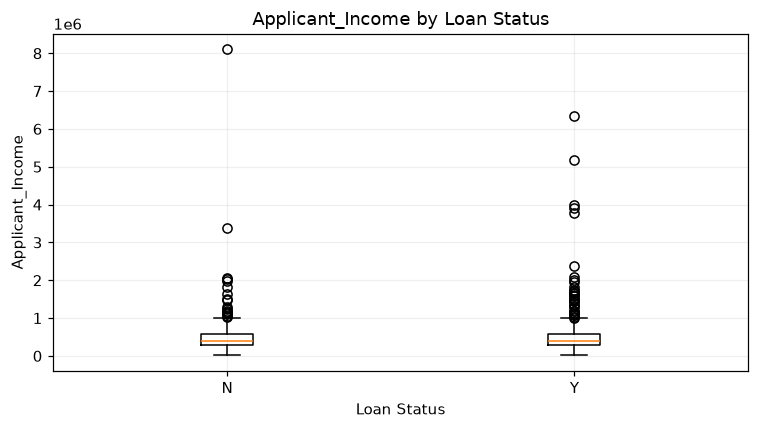

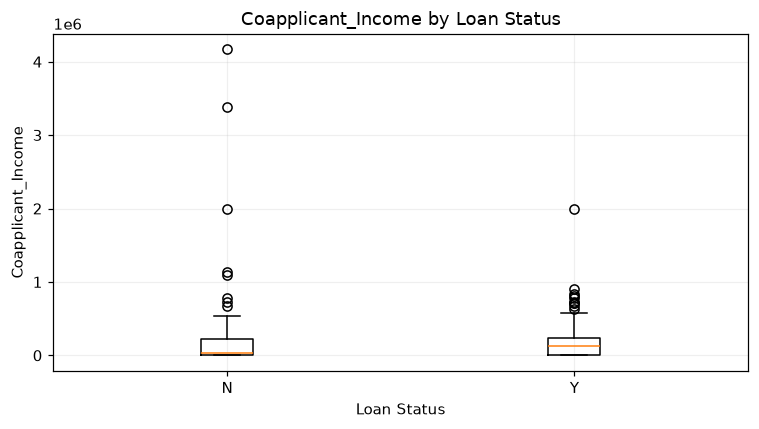

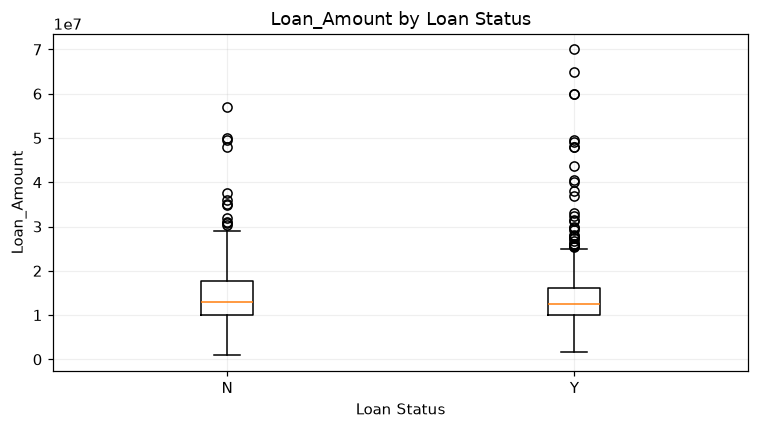

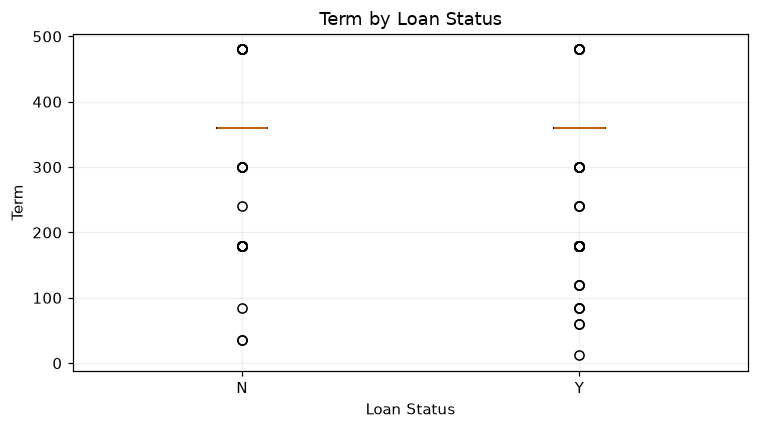

In [14]:
for col in ["Applicant_Income", "Coapplicant_Income", "Loan_Amount", "Term"]:
    groups = [
        train.loc[train[TARGET] == "N", col].dropna(),
        train.loc[train[TARGET] == "Y", col].dropna(),]
    
    plt.figure(figsize=(7, 4))
    plt.boxplot(groups, tick_labels=["N", "Y"], showfliers=True)
    plt.xlabel("Loan Status")
    plt.ylabel(col)
    plt.title(f"{col} by Loan Status")
    plt.tight_layout()
    plt.show()

<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
## ۳-۴. شناسایی داده‌های پرت با IQR
</div>


In [15]:
continuous_for_outlier = ["Applicant_Income", "Coapplicant_Income", "Loan_Amount"]
outlier_rows = []

for col in continuous_for_outlier:
    values = train[col].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((values < lower) | (values > upper)).sum())
    outlier_rows.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower bound": lower,
        "Upper bound": upper,
        "Outlier count": count,
        "Outlier percent": count / len(values) * 100,})

display(pd.DataFrame(outlier_rows))
print("تصمیم نهایی درباره مدیریت داده‌های پرت با مقایسه عملکرد مدل در اعتبارسنجی متقابل گرفته می‌شود.")

,Feature,Q1,Q3,IQR,Lower bound,Upper bound,Outlier count,Outlier percent
0,Applicant_Income,"287,750.0000","579,500.0000","291,750.0000","-149,875.0000","1,017,125.0000",50,8.1433
1,Coapplicant_Income,0.0000,"229,725.0000","229,725.0000","-344,587.5000","574,312.5000",18,2.9316
2,Loan_Amount,"10,000,000.0000","16,800,000.0000","6,800,000.0000","-200,000.0000","27,000,000.0000",39,6.5767


تصمیم نهایی درباره مدیریت داده‌های پرت با مقایسه عملکرد مدل در اعتبارسنجی متقابل گرفته می‌شود.


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
## ۳-۵. ماتریس همبستگی متغیرهای عددی
</div>


,Applicant_Income,Coapplicant_Income,Loan_Amount,Term,Credit_History,Status
Applicant_Income,1.0000,-0.1166,0.5709,-0.0453,-0.0147,-0.0047
Coapplicant_Income,-0.1166,1.0000,0.1885,-0.0599,-0.0021,-0.0592
Loan_Amount,0.5709,0.1885,1.0000,0.0395,-0.0084,-0.0373
Term,-0.0453,-0.0599,0.0395,1.0000,0.0015,-0.0213
Credit_History,-0.0147,-0.0021,-0.0084,0.0015,1.0000,0.5617
Status,-0.0047,-0.0592,-0.0373,-0.0213,0.5617,1.0000


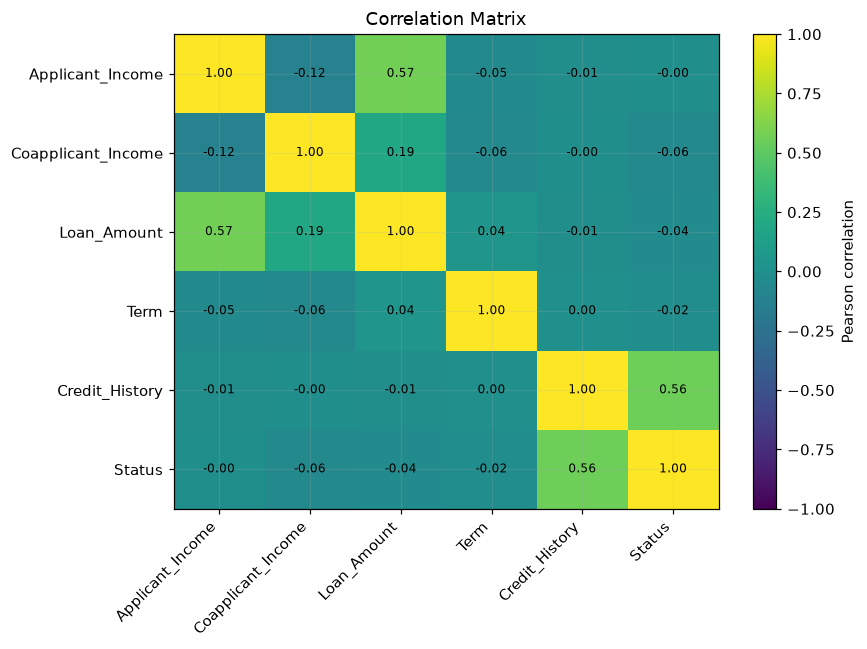

In [16]:
corr_df = train[numeric_original].copy()
corr_df[TARGET] = train[TARGET].map({"N": 0, "Y": 1})
corr = corr_df.corr(numeric_only=True)

display(corr)

plt.figure(figsize=(8, 6))
image = plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(image, label="Pearson correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Correlation Matrix")
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.show()

<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
## ۳-۶. جمع‌بندی اولیه EDA

- داده آموزش دارای ۶۱۴ نمونه و متغیر هدف باینری است.
- کلاس تأییدشده فراوان‌تر از کلاس ردشده است؛ در نتیجه ارزیابی فقط با Accuracy کافی نیست.
- چند ستون دارای مقدار گمشده‌اند و باید روش جایگزینی آن‌ها با مقایسه اعتبارسنجی انتخاب شود.
- فایل تست برچسب ندارد و برای جلوگیری از نشت اطلاعات تا پایان تحلیل کنار گذاشته می‌شود.
</div>


<div style="background:#D9E4DE;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

# ۴. طراحی و ساخت Pipeline بدون نشت اطلاعات
</div>


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
## ۴-۱. جداسازی ویژگی‌ها و متغیر هدف
</div>


In [17]:
X = train.drop(columns=[TARGET]).copy()
y = train[TARGET].map({"N": 0, "Y": 1}).astype(int)
X_external_test = test.copy()

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,)

split_summary = pd.DataFrame({
    "Full": y.value_counts(normalize=True),
    "Train": y_train.value_counts(normalize=True),
    "Validation": y_valid.value_counts(normalize=True),}).fillna(0)

display(split_summary)
print(f"ابعاد X_train: {X_train.shape}")
print(f"ابعاد X_valid: {X_valid.shape}")
print(f"ابعاد آزمون نهایی: {X_external_test.shape}")

,Full,Train,Validation
Status,,,
1,0.6873,0.6864,0.6911
0,0.3127,0.3136,0.3089


ابعاد X_train: (491, 11)
ابعاد X_valid: (123, 11)
ابعاد آزمون نهایی: (367, 11)


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
## ۴-۲. مهندسی ویژگی
</div>


In [18]:
class LoanFeatureEngineer(BaseEstimator, TransformerMixin):
    # ساخت ویژگی‌های مالی جدید از روی ستون‌های خام

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        data = X.copy()
        total_income = data["Applicant_Income"] + data["Coapplicant_Income"]
        safe_income = total_income.replace(0, np.nan)
        safe_term = data["Term"].replace(0, np.nan)

        data["Total_Income"] = total_income
        data["Loan_to_Income"] = data["Loan_Amount"] / safe_income
        data["Loan_Amount_per_Term"] = data["Loan_Amount"] / safe_term
        data["Has_Coapplicant"] = (data["Coapplicant_Income"].fillna(0) > 0).astype(float)
        return data


class QuantileClipper(BaseEstimator, TransformerMixin):

    def __init__(self, lower_quantile=0.01, upper_quantile=0.99):
        self.lower_quantile = lower_quantile
        self.upper_quantile = upper_quantile

    def fit(self, X, y=None):
        array = np.asarray(X, dtype=float)
        self.lower_bounds_ = np.nanquantile(array, self.lower_quantile, axis=0)
        self.upper_bounds_ = np.nanquantile(array, self.upper_quantile, axis=0)
        return self

    def transform(self, X):
        array = np.asarray(X, dtype=float)
        return np.clip(array, self.lower_bounds_, self.upper_bounds_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
## ۴-۳. توابع پیش‌پردازش و ارزیابی
</div>


In [19]:
CONTINUOUS_FEATURES = [
    "Applicant_Income", "Coapplicant_Income", "Loan_Amount",
    "Total_Income", "Loan_to_Income", "Loan_Amount_per_Term"]

DISCRETE_NUMERIC_FEATURES = ["Term", "Credit_History", "Has_Coapplicant"]
CATEGORICAL_FEATURES = [
    "Gender", "Married", "Dependents", "Education", "Self_Employed", "Area"]

def make_numeric_imputer(method):
    if method == "median":
        return SimpleImputer(strategy="median")
    if method == "mean":
        return SimpleImputer(strategy="mean")
    if method == "knn":
        return KNNImputer(n_neighbors=5, weights="distance")
    raise ValueError(f"روش Imputation ناشناخته: {method}")

def make_scaler(method):
    if method == "standard":
        return StandardScaler()
    if method == "minmax":
        return MinMaxScaler()
    if method == "robust":
        return RobustScaler()
    if method == "none":
        return "passthrough"
    raise ValueError(f"روش Scaling ناشناخته: {method}")

def build_preprocessor(
    imputer_method="median",
    scaler_method="standard",
    outlier_method="none",
    use_log=False,):

    continuous_steps = [("imputer", make_numeric_imputer(imputer_method))]

    if outlier_method == "winsor":
        continuous_steps.append(("clipper", QuantileClipper(0.01, 0.99)))
    elif outlier_method != "none":
        raise ValueError(f"روش Outlier ناشناخته: {outlier_method}")

    if use_log:
        continuous_steps.append(
            ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")))

    continuous_steps.append(("scaler", make_scaler(scaler_method)))

    continuous_pipeline = SkPipeline(continuous_steps)
    discrete_pipeline = SkPipeline([
        ("imputer", make_numeric_imputer(imputer_method)),
        ("scaler", make_scaler(scaler_method)),])
    
    categorical_pipeline = SkPipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),])

    return ColumnTransformer(
        transformers=[
            ("continuous", continuous_pipeline, CONTINUOUS_FEATURES),
            ("discrete", discrete_pipeline, DISCRETE_NUMERIC_FEATURES),
            ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
        ],
        remainder="drop",
        verbose_feature_names_out=True,)


SCORING = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",}


def make_pipeline(model, preprocessor, sampler="passthrough"):
    return ImbPipeline([
        ("feature_engineering", LoanFeatureEngineer()),
        ("preprocess", preprocessor),
        ("sampler", sampler),
        ("model", model),])


def cv_evaluate_configuration(name, pipeline):
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=CV,
        scoring=SCORING,
        n_jobs=N_JOBS,
        return_train_score=False,
        error_score="raise",)
    
    row = {"Method": name}
    for metric in SCORING:
        row[f"CV_{metric}_mean"] = scores[f"test_{metric}"].mean()
        row[f"CV_{metric}_std"] = scores[f"test_{metric}"].std()
    return row


def probability_scores(estimator, X_data):
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(X_data)[:, 1]
    decision = estimator.decision_function(X_data)
    decision = np.asarray(decision, dtype=float)
    return (decision - decision.min()) / (decision.max() - decision.min() + 1e-12)


def classification_metrics(y_true, y_pred, y_score):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, y_score),
        "PR_AUC": average_precision_score(y_true, y_score),}

<div style="background:#D9E4DE;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

# ۵. مقایسه روش‌های پیش‌پردازش
</div>


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۵-۱. مقایسه روش‌های مدیریت مقادیر گمشده
</div>


In [20]:
imputation_results = []
for method in ["mean", "median", "knn"]:
    preprocessor = build_preprocessor(
        imputer_method=method,
        scaler_method="standard",
        outlier_method="none",
        use_log=False,)
    
    pipeline = make_pipeline(
        LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
        preprocessor,)
    
    imputation_results.append(cv_evaluate_configuration(method, pipeline))

imputation_results = pd.DataFrame(imputation_results).sort_values(
    "CV_f1_mean", ascending=False
).reset_index(drop=True)
display(imputation_results)

best_imputer = imputation_results.loc[0, "Method"]
print(f"روش منتخب Imputation: {best_imputer}")

,Method,CV_accuracy_mean,CV_accuracy_std,CV_balanced_accuracy_mean,CV_balanced_accuracy_std,CV_precision_mean,CV_precision_std,CV_recall_mean,CV_recall_std,CV_f1_mean,CV_f1_std,CV_roc_auc_mean,CV_roc_auc_std,CV_average_precision_mean,CV_average_precision_std
0,mean,0.7882,0.0032,0.6835,0.0128,0.7796,0.0097,0.9644,0.0144,0.8621,0.0011,0.7352,0.0132,0.8335,0.0153
1,knn,0.7841,0.0051,0.6823,0.0056,0.7798,0.0068,0.9556,0.0216,0.8586,0.0054,0.7304,0.0177,0.8299,0.0228
2,median,0.7821,0.0102,0.6773,0.0153,0.7766,0.0113,0.9585,0.0167,0.8579,0.0070,0.7324,0.0035,0.8319,0.0141


روش منتخب Imputation: mean


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۵-۲. مقایسه روش‌های مقیاس‌بندی
</div>


In [21]:
scaling_results = []
for method in ["standard", "minmax", "robust", "none"]:
    preprocessor = build_preprocessor(
        imputer_method=best_imputer,
        scaler_method=method,
        outlier_method="none",
        use_log=False,)
    
    pipeline = make_pipeline(
        LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
        preprocessor,)
    
    scaling_results.append(cv_evaluate_configuration(method, pipeline))

scaling_results = pd.DataFrame(scaling_results).sort_values(
    "CV_f1_mean", ascending=False
).reset_index(drop=True)
display(scaling_results)

best_scaler = scaling_results.loc[0, "Method"]
print(f"روش منتخب Scaling: {best_scaler}")

,Method,CV_accuracy_mean,CV_accuracy_std,CV_balanced_accuracy_mean,CV_balanced_accuracy_std,CV_precision_mean,CV_precision_std,CV_recall_mean,CV_recall_std,CV_f1_mean,CV_f1_std,CV_roc_auc_mean,CV_roc_auc_std,CV_average_precision_mean,CV_average_precision_std
0,minmax,0.7922,0.0134,0.6848,0.0232,0.7794,0.0156,0.9733,0.0072,0.8655,0.0073,0.7441,0.0222,0.8395,0.0115
1,robust,0.7882,0.0077,0.6818,0.0155,0.7783,0.0112,0.9674,0.0110,0.8625,0.0042,0.7349,0.0121,0.8340,0.0148
2,standard,0.7882,0.0032,0.6835,0.0128,0.7796,0.0097,0.9644,0.0144,0.8621,0.0011,0.7352,0.0132,0.8335,0.0153
3,none,0.6742,0.0118,0.4929,0.0077,0.6832,0.0058,0.9792,0.0151,0.8048,0.0084,0.4309,0.0086,0.6328,0.0131


روش منتخب Scaling: minmax


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۵-۳. مقایسه مدیریت داده‌های پرت
</div>


In [22]:
outlier_configs = [
    ("none", "none", False),
    ("log1p", "none", True),
    ("winsor", "winsor", False),
    ("winsor_log1p", "winsor", True),]

outlier_results = []
for label, outlier_method, use_log in outlier_configs:
    preprocessor = build_preprocessor(
        imputer_method=best_imputer,
        scaler_method=best_scaler,
        outlier_method=outlier_method,
        use_log=use_log,)
    
    pipeline = make_pipeline(
        LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
        preprocessor,)
    
    outlier_results.append(cv_evaluate_configuration(label, pipeline))

outlier_results = pd.DataFrame(outlier_results).sort_values(
    "CV_f1_mean", ascending=False
).reset_index(drop=True)
display(outlier_results)

best_outlier_label = outlier_results.loc[0, "Method"]
selected_outlier = next(item for item in outlier_configs if item[0] == best_outlier_label)
best_outlier_method = selected_outlier[1]
best_use_log = selected_outlier[2]

print(f"سناریوی منتخب مدیریت داده پرت: {best_outlier_label}")

,Method,CV_accuracy_mean,CV_accuracy_std,CV_balanced_accuracy_mean,CV_balanced_accuracy_std,CV_precision_mean,CV_precision_std,CV_recall_mean,CV_recall_std,CV_f1_mean,CV_f1_std,CV_roc_auc_mean,CV_roc_auc_std,CV_average_precision_mean,CV_average_precision_std
0,log1p,0.7943,0.0162,0.6863,0.0253,0.7799,0.0163,0.9763,0.0042,0.8670,0.0094,0.7436,0.0242,0.8387,0.0121
1,winsor,0.7943,0.0162,0.6863,0.0253,0.7799,0.0163,0.9763,0.0042,0.8670,0.0094,0.7454,0.0185,0.8452,0.0092
2,winsor_log1p,0.7943,0.0162,0.6863,0.0253,0.7799,0.0163,0.9763,0.0042,0.8670,0.0094,0.7435,0.0228,0.8396,0.0109
3,none,0.7922,0.0134,0.6848,0.0232,0.7794,0.0156,0.9733,0.0072,0.8655,0.0073,0.7441,0.0222,0.8395,0.0115


سناریوی منتخب مدیریت داده پرت: log1p


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۵-۴. مقایسه روش‌های مدیریت عدم تعادل کلاس
</div>


In [23]:
selected_preprocessor = build_preprocessor(
    imputer_method=best_imputer,
    scaler_method=best_scaler,
    outlier_method=best_outlier_method,
    use_log=best_use_log,)

imbalance_configs = [
    ("No resampling", "passthrough", None),
    ("RandomOverSampler", RandomOverSampler(random_state=RANDOM_STATE), None),
    ("SMOTE", SMOTE(random_state=RANDOM_STATE, k_neighbors=5), None),
    ("ClassWeight", "passthrough", "balanced"),]

imbalance_results = []
for label, sampler, class_weight in imbalance_configs:
    model = LogisticRegression(
        max_iter=5000,
        random_state=RANDOM_STATE,
        class_weight=class_weight,)
    
    pipeline = make_pipeline(model, selected_preprocessor, sampler=sampler)
    imbalance_results.append(cv_evaluate_configuration(label, pipeline))

imbalance_results = pd.DataFrame(imbalance_results).sort_values(
    "CV_f1_mean", ascending=False
).reset_index(drop=True)
display(imbalance_results)

sampler_only_results = imbalance_results[
    imbalance_results["Method"].isin(["No resampling", "RandomOverSampler", "SMOTE"])
].sort_values("CV_f1_mean", ascending=False)

best_sampler_label = sampler_only_results.iloc[0]["Method"]
if best_sampler_label == "RandomOverSampler":
    selected_sampler = RandomOverSampler(random_state=RANDOM_STATE)
elif best_sampler_label == "SMOTE":
    selected_sampler = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
else:
    selected_sampler = "passthrough"

print(f"نمونه‌برداری منتخب برای مقایسه مدل‌ها: {best_sampler_label}")

,Method,CV_accuracy_mean,CV_accuracy_std,CV_balanced_accuracy_mean,CV_balanced_accuracy_std,CV_precision_mean,CV_precision_std,CV_recall_mean,CV_recall_std,CV_f1_mean,CV_f1_std,CV_roc_auc_mean,CV_roc_auc_std,CV_average_precision_mean,CV_average_precision_std
0,No resampling,0.7943,0.0162,0.6863,0.0253,0.7799,0.0163,0.9763,0.0042,0.8670,0.0094,0.7436,0.0242,0.8387,0.0121
1,SMOTE,0.7535,0.0254,0.6899,0.0317,0.7968,0.0191,0.8605,0.0183,0.8274,0.0171,0.7310,0.0221,0.8173,0.0062
2,ClassWeight,0.7250,0.0137,0.6711,0.0213,0.7906,0.0170,0.8160,0.0110,0.8029,0.0087,0.7408,0.0248,0.8353,0.0125
3,RandomOverSampler,0.7230,0.0174,0.6767,0.0267,0.7970,0.0215,0.8012,0.0080,0.7989,0.0111,0.7334,0.0159,0.8284,0.0174


نمونه‌برداری منتخب برای مقایسه مدل‌ها: No resampling


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۵-۵. خلاصه تصمیم‌های پیش‌پردازش
</div>


In [ ]:
preprocessing_decisions = pd.DataFrame([
    {"Component": "Numeric imputation", "Selected": best_imputer},
    {"Component": "Scaling", "Selected": best_scaler},
    {"Component": "Outlier/skew treatment", "Selected": best_outlier_label},
    {"Component": "Resampling", "Selected": best_sampler_label},])

display(preprocessing_decisions)

,Component,Selected
0,Numeric imputation,mean
1,Scaling,minmax
2,Outlier/skew treatment,log1p
3,Resampling,No resampling


                Component       Selected
0      Numeric imputation           mean
1                 Scaling         minmax
2  Outlier/skew treatment          log1p
3              Resampling  No resampling


<div style="background:#D9E4DE;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
# ۶. مدل‌های مبنا پیش از تنظیم ابرپارامتر

- Logistic Regression؛
- KNN؛
- SVM؛
- Decision Tree؛
- Random Forest؛
- Gradient Boosting.
</div>


In [26]:
baseline_models = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(probability=True, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=N_JOBS),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),}

baseline_rows = []
baseline_estimators = {}

for name, model in baseline_models.items():
    start = time.time()
    pipeline = make_pipeline(
        model=clone(model),
        preprocessor=clone(selected_preprocessor),
        sampler=clone(selected_sampler) if selected_sampler != "passthrough" else "passthrough",)

    cv_scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=CV,
        scoring=SCORING,
        n_jobs=N_JOBS,
        error_score="raise",)

    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_valid)
    score = probability_scores(pipeline, X_valid)
    holdout = classification_metrics(y_valid, pred, score)

    row = {
        "Model": name,
        "CV_F1_mean": cv_scores["test_f1"].mean(),
        "CV_F1_std": cv_scores["test_f1"].std(),
        "CV_ROC_AUC_mean": cv_scores["test_roc_auc"].mean(),
        "CV_Balanced_Accuracy_mean": cv_scores["test_balanced_accuracy"].mean(),
        **{f"Validation_{k}": v for k, v in holdout.items()},
        "Runtime_seconds": time.time() - start,}
    
    baseline_rows.append(row)
    baseline_estimators[name] = pipeline
    print(f"مدل مبنا تکمیل شد: {name}")

baseline_results = pd.DataFrame(baseline_rows).sort_values(
    "CV_F1_mean", ascending=False
).reset_index(drop=True)
display(baseline_results)

مدل مبنا تکمیل شد: Logistic Regression
مدل مبنا تکمیل شد: KNN
مدل مبنا تکمیل شد: SVM
مدل مبنا تکمیل شد: Decision Tree
مدل مبنا تکمیل شد: Random Forest
مدل مبنا تکمیل شد: Gradient Boosting


,Model,CV_F1_mean,CV_F1_std,CV_ROC_AUC_mean,CV_Balanced_Accuracy_mean,Validation_Accuracy,Validation_Balanced_Accuracy,Validation_Precision,Validation_Recall,Validation_F1,Validation_ROC_AUC,Validation_PR_AUC,Runtime_seconds
0,SVM,0.8700,0.0102,0.7289,0.6893,0.8537,0.7704,0.8317,0.9882,0.9032,0.7755,0.8592,0.9660
1,Logistic Regression,0.8670,0.0094,0.7436,0.6863,0.8537,0.7704,0.8317,0.9882,0.9032,0.8567,0.9186,8.2084
2,Random Forest,0.8530,0.0052,0.7764,0.6832,0.8618,0.8127,0.8696,0.9412,0.9040,0.8492,0.8952,5.3970
3,Gradient Boosting,0.8466,0.0026,0.7237,0.6857,0.8293,0.7746,0.8478,0.9176,0.8814,0.8121,0.8921,2.2847
4,KNN,0.8079,0.0065,0.6313,0.5787,0.7317,0.6240,0.7549,0.9059,0.8235,0.6929,0.7945,4.1463
5,Decision Tree,0.7891,0.0233,0.6643,0.6643,0.7642,0.7639,0.8784,0.7647,0.8176,0.7639,0.8343,0.5933


<div style="background:#D9E4DE;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">
    
# ۷. تنظیم ابرپارامترها با Cross-Validation
</div>


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۷-۱. فضای جست‌وجوی هر مدل
</div>


In [29]:
search_specs = {
    "Logistic Regression": {
        "type": "grid",
        "model": LogisticRegression(max_iter=5000, solver="liblinear", random_state=RANDOM_STATE),
        "params": {
            "model__C": [0.1, 1, 10],
            "model__class_weight": [None, "balanced"],
        },
    },
    "KNN": {
        "type": "grid",
        "model": KNeighborsClassifier(),
        "params": {
            "model__n_neighbors": [5, 9, 15],
            "model__weights": ["uniform", "distance"],
        },
    },
    "SVM": {
        "type": "grid",
        "model": SVC(probability=True, random_state=RANDOM_STATE),
        "params": {
            "model__C": [0.1, 1, 10],
            "model__class_weight": [None, "balanced"],
        },
    },
    "Decision Tree": {
        "type": "grid",
        "model": DecisionTreeClassifier(random_state=RANDOM_STATE, min_samples_leaf=3),
        "params": {
            "model__max_depth": [3, 5, 8, None],
            "model__class_weight": [None, "balanced"],
        },
    },
    "Random Forest": {
        "type": "random",
        "model": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS),
        "params": {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 5, 10],
            "model__min_samples_leaf": [1, 4],
            "model__max_features": ["sqrt", 0.7],
            "model__class_weight": [None, "balanced"],
        },
        "n_iter": 5,
    },
    "Gradient Boosting": {
        "type": "random",
        "model": GradientBoostingClassifier(random_state=RANDOM_STATE),
        "params": {
            "model__n_estimators": [50, 100, 150],
            "model__learning_rate": [0.03, 0.05, 0.1],
            "model__max_depth": [1, 2, 3],
            "model__subsample": [0.7, 1.0],
        },
        "n_iter": 5,
    },
}

for name, spec in search_specs.items():
    candidate_count = np.prod([len(v) for v in spec["params"].values()])
    evaluated_count = candidate_count if spec["type"] == "grid" else spec["n_iter"]
    print(
        f"{name}: نوع جست‌وجو={spec['type']}، "
        f"اندازه فضای کامل={candidate_count}، تعداد ارزیابی={evaluated_count}"
    )

Logistic Regression: نوع جست‌وجو=grid، اندازه فضای کامل=6، تعداد ارزیابی=6
KNN: نوع جست‌وجو=grid، اندازه فضای کامل=6، تعداد ارزیابی=6
SVM: نوع جست‌وجو=grid، اندازه فضای کامل=6، تعداد ارزیابی=6
Decision Tree: نوع جست‌وجو=grid، اندازه فضای کامل=8، تعداد ارزیابی=8
Random Forest: نوع جست‌وجو=random، اندازه فضای کامل=48، تعداد ارزیابی=5
Gradient Boosting: نوع جست‌وجو=random، اندازه فضای کامل=54، تعداد ارزیابی=5


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۷-۲. اجرای جست‌وجو
</div>


In [30]:
tuned_estimators = {}
tuning_rows = []
best_params = {}

for name, spec in search_specs.items():
    start = time.time()
    pipeline = make_pipeline(
        model=clone(spec["model"]),
        preprocessor=clone(selected_preprocessor),
        sampler=clone(selected_sampler) if selected_sampler != "passthrough" else "passthrough",)

    if spec["type"] == "grid":
        search = GridSearchCV(
            estimator=pipeline,
            param_grid=spec["params"],
            scoring=SCORING,
            refit="f1",
            cv=CV,
            n_jobs=N_JOBS,
            return_train_score=True,
            error_score="raise",)
        
    else:
        search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=spec["params"],
            n_iter=spec["n_iter"],
            scoring=SCORING,
            refit="f1",
            cv=CV,
            n_jobs=N_JOBS,
            random_state=RANDOM_STATE,
            return_train_score=True,
            error_score="raise",)

    search.fit(X_train, y_train)
    best_estimator = search.best_estimator_
    tuned_estimators[name] = best_estimator
    best_params[name] = search.best_params_

    valid_pred = best_estimator.predict(X_valid)
    valid_score = probability_scores(best_estimator, X_valid)
    holdout_metrics = classification_metrics(y_valid, valid_pred, valid_score)

    idx = search.best_index_
    row = {
        "Model": name,
        "CV_F1_mean": search.cv_results_["mean_test_f1"][idx],
        "CV_F1_std": search.cv_results_["std_test_f1"][idx],
        "CV_Train_F1_mean": search.cv_results_["mean_train_f1"][idx],
        "CV_ROC_AUC_mean": search.cv_results_["mean_test_roc_auc"][idx],
        "CV_Balanced_Accuracy_mean": search.cv_results_["mean_test_balanced_accuracy"][idx],
        **{f"Validation_{k}": v for k, v in holdout_metrics.items()},
        "Runtime_seconds": time.time() - start,}
    
    tuning_rows.append(row)
    print(f"جست‌وجوی {name} تکمیل شد. بهترین CV-F1: {search.best_score_:.4f}")

    print("بهترین پارامترها:")
    print(search.best_params_)
    print("-" * 80)

tuned_results = pd.DataFrame(tuning_rows).sort_values(
    "CV_F1_mean", ascending=False
).reset_index(drop=True)
display(tuned_results)

جست‌وجوی Logistic Regression تکمیل شد. بهترین CV-F1: 0.8670
بهترین پارامترها:
{'model__C': 1, 'model__class_weight': None}
--------------------------------------------------------------------------------
جست‌وجوی KNN تکمیل شد. بهترین CV-F1: 0.8279
بهترین پارامترها:
{'model__n_neighbors': 15, 'model__weights': 'distance'}
--------------------------------------------------------------------------------
جست‌وجوی SVM تکمیل شد. بهترین CV-F1: 0.8700
بهترین پارامترها:
{'model__C': 1, 'model__class_weight': None}
--------------------------------------------------------------------------------
جست‌وجوی Decision Tree تکمیل شد. بهترین CV-F1: 0.8693
بهترین پارامترها:
{'model__class_weight': 'balanced', 'model__max_depth': 3}
--------------------------------------------------------------------------------
جست‌وجوی Random Forest تکمیل شد. بهترین CV-F1: 0.8262
بهترین پارامترها:
{'model__n_estimators': 200, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 10, 'model__cl

,Model,CV_F1_mean,CV_F1_std,CV_Train_F1_mean,CV_ROC_AUC_mean,CV_Balanced_Accuracy_mean,Validation_Accuracy,Validation_Balanced_Accuracy,Validation_Precision,Validation_Recall,Validation_F1,Validation_ROC_AUC,Validation_PR_AUC,Runtime_seconds
0,Gradient Boosting,0.8700,0.0102,0.8711,0.7285,0.6893,0.8699,0.7967,0.8485,0.9882,0.9130,0.8591,0.8941,5.1394
1,SVM,0.8700,0.0102,0.8711,0.7289,0.6893,0.8537,0.7704,0.8317,0.9882,0.9032,0.7755,0.8592,5.1394
2,Decision Tree,0.8693,0.0047,0.8804,0.6903,0.7013,0.8537,0.7923,0.8526,0.9529,0.9000,0.8305,0.8732,4.3182
3,Logistic Regression,0.8670,0.0094,0.8677,0.7423,0.6863,0.8537,0.7704,0.8317,0.9882,0.9032,0.8588,0.9201,10.3305
4,KNN,0.8279,0.0075,1.0000,0.6669,0.5758,0.7480,0.6139,0.7455,0.9647,0.8410,0.7381,0.8520,3.9257
5,Random Forest,0.8262,0.0077,0.9647,0.7639,0.7020,0.7967,0.7875,0.8846,0.8118,0.8466,0.8508,0.9012,13.9552


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۷-۳. مقایسه قبل و بعد از تنظیم ابرپارامترها
</div>


In [31]:
comparison_before_after = baseline_results[
    ["Model", "CV_F1_mean", "Validation_F1", "Validation_ROC_AUC"]
].merge(
    tuned_results[["Model", "CV_F1_mean", "Validation_F1", "Validation_ROC_AUC"]],
    on="Model",
    suffixes=("_Before", "_After"),)

comparison_before_after["CV_F1_Improvement"] = (
    comparison_before_after["CV_F1_mean_After"] - comparison_before_after["CV_F1_mean_Before"])

comparison_before_after["Validation_F1_Improvement"] = (
    comparison_before_after["Validation_F1_After"] - comparison_before_after["Validation_F1_Before"])

display(comparison_before_after.sort_values("CV_F1_mean_After", ascending=False))

,Model,CV_F1_mean_Before,Validation_F1_Before,Validation_ROC_AUC_Before,CV_F1_mean_After,Validation_F1_After,Validation_ROC_AUC_After,CV_F1_Improvement,Validation_F1_Improvement
0,SVM,0.8700,0.9032,0.7755,0.8700,0.9032,0.7755,0.0000,0.0000
3,Gradient Boosting,0.8466,0.8814,0.8121,0.8700,0.9130,0.8591,0.0234,0.0317
5,Decision Tree,0.7891,0.8176,0.7639,0.8693,0.9000,0.8305,0.0802,0.0824
1,Logistic Regression,0.8670,0.9032,0.8567,0.8670,0.9032,0.8588,0.0000,0.0000
4,KNN,0.8079,0.8235,0.6929,0.8279,0.8410,0.7381,0.0200,0.0175
2,Random Forest,0.8530,0.9040,0.8492,0.8262,0.8466,0.8508,-0.0268,-0.0573


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۷-۴. تحلیل پایداری و انتخاب مدل برتر
</div>


In [32]:
stability_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=RANDOM_STATE,)

top_model_names = tuned_results.head(4)["Model"].tolist()
stability_rows = []

for name in top_model_names:
    estimator = clone(tuned_estimators[name])
    scores = cross_validate(
        estimator,
        X_train,
        y_train,
        cv=stability_cv,
        scoring=SCORING,
        n_jobs=N_JOBS,
        error_score="raise",)
    
    stability_rows.append({
        "Model": name,
        "Repeated_CV_F1_mean": scores["test_f1"].mean(),
        "Repeated_CV_F1_std": scores["test_f1"].std(),
        "Repeated_CV_Balanced_Accuracy_mean": scores["test_balanced_accuracy"].mean(),
        "Repeated_CV_ROC_AUC_mean": scores["test_roc_auc"].mean(),
        "Repeated_CV_PR_AUC_mean": scores["test_average_precision"].mean(),})

stability_results = pd.DataFrame(stability_rows).sort_values(
    [
        "Repeated_CV_F1_mean",
        "Repeated_CV_Balanced_Accuracy_mean",
        "Repeated_CV_ROC_AUC_mean",
    ],
    ascending=False,
).reset_index(drop=True)

display(stability_results)

best_model_name = stability_results.iloc[0]["Model"]
best_estimator = tuned_estimators[best_model_name]

print(f"مدل منتخب پس از تحلیل پایداری: {best_model_name}")
print("بهترین پارامترها:")
print(best_params[best_model_name])

valid_pred_default = best_estimator.predict(X_valid)
valid_score = probability_scores(best_estimator, X_valid)

print("\nگزارش طبقه‌بندی روی مجموعه اعتبارسنجی نهایی با آستانه پیش‌فرض:")
print(classification_report(
    y_valid,
    valid_pred_default,
    target_names=["Rejected (N)", "Approved (Y)"],
    digits=4,
    zero_division=0,))

,Model,Repeated_CV_F1_mean,Repeated_CV_F1_std,Repeated_CV_Balanced_Accuracy_mean,Repeated_CV_ROC_AUC_mean,Repeated_CV_PR_AUC_mean
0,SVM,0.8707,0.0213,0.6904,0.7233,0.8118
1,Gradient Boosting,0.8701,0.0208,0.6900,0.7198,0.8031
2,Logistic Regression,0.8671,0.0197,0.6876,0.7347,0.8339
3,Decision Tree,0.8420,0.0702,0.6813,0.6900,0.7831


مدل منتخب پس از تحلیل پایداری: SVM
بهترین پارامترها:
{'model__C': 1, 'model__class_weight': None}

گزارش طبقه‌بندی روی مجموعه اعتبارسنجی نهایی با آستانه پیش‌فرض:
              precision    recall  f1-score   support

Rejected (N)     0.9545    0.5526    0.7000        38
Approved (Y)     0.8317    0.9882    0.9032        85

    accuracy                         0.8537       123
   macro avg     0.8931    0.7704    0.8016       123
weighted avg     0.8696    0.8537    0.8404       123



<div style="background:#D9E4DE;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

# ۸. ارزیابی و تحلیل جامع مدل‌ها
</div>


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۸-۱. جدول نهایی مقایسه مدل‌ها
</div>


In [33]:
final_comparison_columns = [
    "Model", "CV_F1_mean", "CV_F1_std", "CV_ROC_AUC_mean",
    "CV_Balanced_Accuracy_mean", "Validation_Accuracy",
    "Validation_Balanced_Accuracy", "Validation_Precision",
    "Validation_Recall", "Validation_F1", "Validation_ROC_AUC",
    "Validation_PR_AUC", "Runtime_seconds"]

display(tuned_results[final_comparison_columns])
confusion_rows = []
for name, estimator in tuned_estimators.items():
    pred = estimator.predict(X_valid)
    tn, fp, fn, tp = confusion_matrix(y_valid, pred, labels=[0, 1]).ravel()
    confusion_rows.append({
        "Model": name,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    })

confusion_comparison = pd.DataFrame(confusion_rows).merge(
    tuned_results[["Model", "Validation_F1", "Validation_Balanced_Accuracy"]],
    on="Model",
    how="left",
).sort_values(["Validation_F1", "Validation_Balanced_Accuracy"], ascending=False)

print("مقایسه TN، FP، FN و TP همه مدل‌های تنظیم‌شده روی مجموعه Holdout:")
display(confusion_comparison)


,Model,CV_F1_mean,CV_F1_std,CV_ROC_AUC_mean,CV_Balanced_Accuracy_mean,Validation_Accuracy,Validation_Balanced_Accuracy,Validation_Precision,Validation_Recall,Validation_F1,Validation_ROC_AUC,Validation_PR_AUC,Runtime_seconds
0,Gradient Boosting,0.8700,0.0102,0.7285,0.6893,0.8699,0.7967,0.8485,0.9882,0.9130,0.8591,0.8941,5.1394
1,SVM,0.8700,0.0102,0.7289,0.6893,0.8537,0.7704,0.8317,0.9882,0.9032,0.7755,0.8592,5.1394
2,Decision Tree,0.8693,0.0047,0.6903,0.7013,0.8537,0.7923,0.8526,0.9529,0.9000,0.8305,0.8732,4.3182
3,Logistic Regression,0.8670,0.0094,0.7423,0.6863,0.8537,0.7704,0.8317,0.9882,0.9032,0.8588,0.9201,10.3305
4,KNN,0.8279,0.0075,0.6669,0.5758,0.7480,0.6139,0.7455,0.9647,0.8410,0.7381,0.8520,3.9257
5,Random Forest,0.8262,0.0077,0.7639,0.7020,0.7967,0.7875,0.8846,0.8118,0.8466,0.8508,0.9012,13.9552


مقایسه TN، FP، FN و TP همه مدل‌های تنظیم‌شده روی مجموعه Holdout:


,Model,TN,FP,FN,TP,Validation_F1,Validation_Balanced_Accuracy
5,Gradient Boosting,23,15,1,84,0.9130,0.7967
0,Logistic Regression,21,17,1,84,0.9032,0.7704
2,SVM,21,17,1,84,0.9032,0.7704
3,Decision Tree,24,14,4,81,0.9000,0.7923
4,Random Forest,29,9,16,69,0.8466,0.7875
1,KNN,10,28,3,82,0.8410,0.6139


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۸-۲. ماتریس درهم‌ریختگی مدل منتخب

- **False Positive:** مدل وام را تأیید کرده، اما برچسب واقعی رد بوده است.
- **False Negative:** مدل وام را رد کرده، اما برچسب واقعی تأیید بوده است.
</div>


Confusion Matrix با آستانه پیش‌فرض ۰٫۵:
[[21 17]
 [ 1 84]]
TN=21, FP=17, FN=1, TP=84


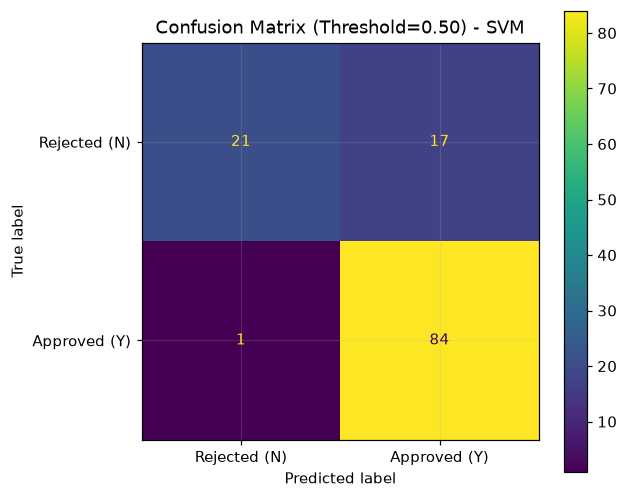

In [34]:
cm = confusion_matrix(y_valid, valid_pred_default, labels=[0, 1])
tn_default, fp_default, fn_default, tp_default = cm.ravel()

print("Confusion Matrix با آستانه پیش‌فرض ۰٫۵:")
print(cm)
print(f"TN={tn_default}, FP={fp_default}, FN={fn_default}, TP={tp_default}")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Rejected (N)", "Approved (Y)"],
).plot(values_format="d", ax=ax)
ax.set_title(f"Confusion Matrix (Threshold=0.50) - {best_model_name}")
fig.tight_layout()
plt.show()


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۸-۳. منحنی ROC مدل‌های تنظیم‌شده
</div>


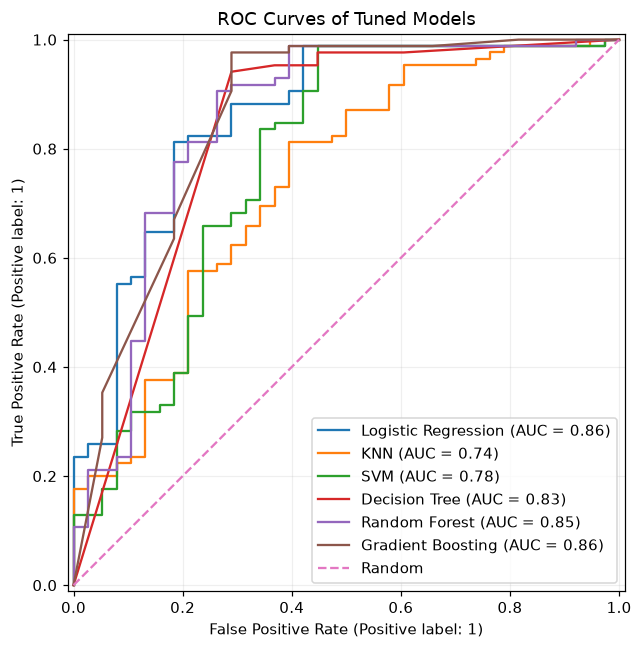

In [35]:
plt.figure(figsize=(8, 6))
ax = plt.gca()
for name, estimator in tuned_estimators.items():
    RocCurveDisplay.from_estimator(estimator, X_valid, y_valid, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", label="Random")
ax.set_title("ROC Curves of Tuned Models")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۸-۴. منحنی Precision-Recall
</div>


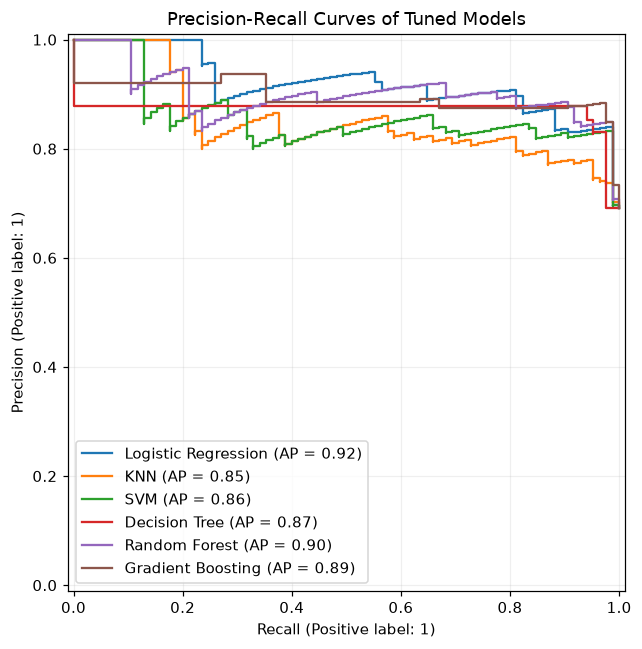

In [36]:
plt.figure(figsize=(8, 6))
ax = plt.gca()
for name, estimator in tuned_estimators.items():
    PrecisionRecallDisplay.from_estimator(estimator, X_valid, y_valid, name=name, ax=ax)
ax.set_title("Precision-Recall Curves of Tuned Models")
ax.legend(loc="best")
plt.tight_layout()
plt.show()

<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۸-۵. تنظیم آستانه تصمیم با پیش‌بینی‌های Out-of-Fold
</div>


,Threshold,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,0.5000,0.8537,0.7704,0.8317,0.9882,0.9032,0.7755,0.8592
1,0.5450,0.8455,0.7646,0.8300,0.9765,0.8973,0.7755,0.8592


آستانه بهینه‌شده با OOF: 0.545


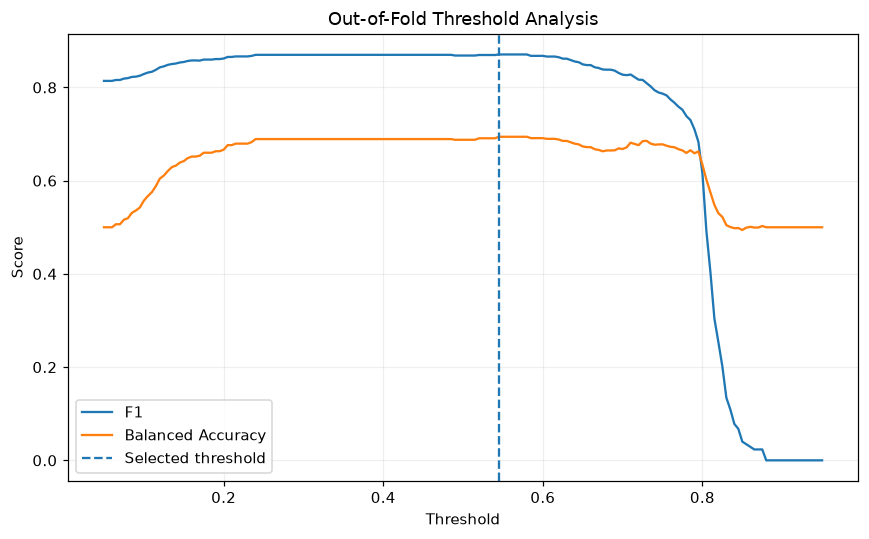

ماتریس درهم‌ریختگی آستانه بهینه‌شده: TN=21, FP=17, FN=2, TP=83


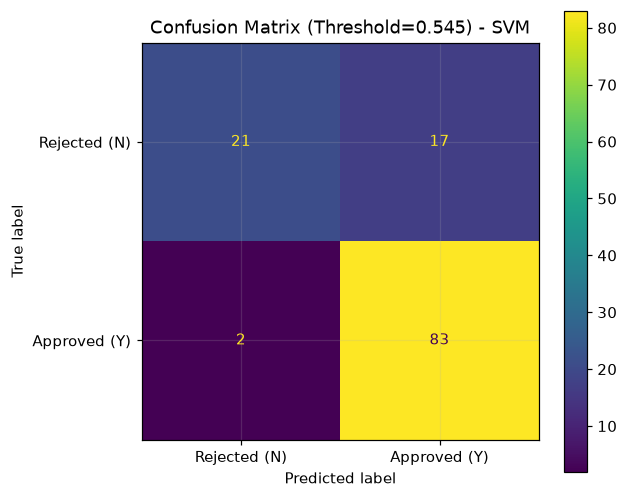

In [37]:
def find_best_threshold(y_true, probabilities, metric="f1"):
    thresholds = np.linspace(0.05, 0.95, 181)
    rows = []
    for threshold in thresholds:
        pred = (probabilities >= threshold).astype(int)
        rows.append({
            "threshold": threshold,
            "f1": f1_score(y_true, pred, zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
        })
    table = pd.DataFrame(rows)
    best_row = table.sort_values([metric, "balanced_accuracy"], ascending=False).iloc[0]
    return float(best_row["threshold"]), table


oof_probabilities = cross_val_predict(
    clone(best_estimator),
    X_train,
    y_train,
    cv=CV,
    method="predict_proba",
    n_jobs=N_JOBS,
)[:, 1]

optimized_threshold, threshold_table = find_best_threshold(
    y_train,
    oof_probabilities,
    metric="f1",
)

valid_pred_optimized = (valid_score >= optimized_threshold).astype(int)
optimized_metrics = classification_metrics(y_valid, valid_pred_optimized, valid_score)
default_metrics = classification_metrics(y_valid, valid_pred_default, valid_score)

threshold_comparison = pd.DataFrame([
    {"Threshold": 0.50, **default_metrics},
    {"Threshold": optimized_threshold, **optimized_metrics},
])
display(threshold_comparison)

print(f"آستانه بهینه‌شده با OOF: {optimized_threshold:.3f}")

plt.figure(figsize=(8, 5))
plt.plot(threshold_table["threshold"], threshold_table["f1"], label="F1")
plt.plot(
    threshold_table["threshold"],
    threshold_table["balanced_accuracy"],
    label="Balanced Accuracy",
)
plt.axvline(optimized_threshold, linestyle="--", label="Selected threshold")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Out-of-Fold Threshold Analysis")
plt.legend()
plt.tight_layout()
plt.show()
optimized_cm = confusion_matrix(y_valid, valid_pred_optimized, labels=[0, 1])
tn_opt, fp_opt, fn_opt, tp_opt = optimized_cm.ravel()
print(f"ماتریس درهم‌ریختگی آستانه بهینه‌شده: TN={tn_opt}, FP={fp_opt}, FN={fn_opt}, TP={tp_opt}")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=optimized_cm,
    display_labels=["Rejected (N)", "Approved (Y)"],
).plot(values_format="d", ax=ax)
ax.set_title(f"Confusion Matrix (Threshold={optimized_threshold:.3f}) - {best_model_name}")
fig.tight_layout()
plt.show()


<div style="background:#D9E4DE;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

# ۹. تحلیل خطاها
</div>


In [39]:
error_analysis = X_valid.copy()
error_analysis["Actual"] = y_valid.map({0: "N", 1: "Y"})
error_analysis["Predicted"] = pd.Series(valid_pred_optimized, index=X_valid.index).map({0: "N", 1: "Y"})
error_analysis["Approval_Probability"] = valid_score

conditions = [
    (error_analysis["Actual"] == "N") & (error_analysis["Predicted"] == "Y"),
    (error_analysis["Actual"] == "Y") & (error_analysis["Predicted"] == "N"),]

error_analysis["Error_Type"] = np.select(
    conditions,
    ["False Positive", "False Negative"],
    default="Correct",)

print("تعداد انواع نتیجه:")
display(error_analysis["Error_Type"].value_counts().to_frame("Count"))

print("نمونه‌های False Positive با بیشترین احتمال تأیید:")
display(
    error_analysis[error_analysis["Error_Type"] == "False Positive"]
    .sort_values("Approval_Probability", ascending=False)
    .head(10))

print("نمونه‌های False Negative با کمترین احتمال تأیید:")
display(
    error_analysis[error_analysis["Error_Type"] == "False Negative"]
    .sort_values("Approval_Probability", ascending=True)
    .head(10))

تعداد انواع نتیجه:


,Count
Error_Type,
Correct,104
False Positive,17
False Negative,2


نمونه‌های False Positive با بیشترین احتمال تأیید:


,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Term,Credit_History,Area,Actual,Predicted,Approval_Probability,Error_Type
216,Male,Yes,0,Graduate,No,"15,000.0000","180,000.0000","13,500,000.0000",360.0000,1.0000,Rural,N,Y,0.8201,False Positive
487,Male,Yes,1,Graduate,No,"1,833,300.0000",0.0000,"50,000,000.0000",360.0000,1.0000,Urban,N,Y,0.8182,False Positive
314,NaN,Yes,0,Graduate,No,"247,300.0000","184,300.0000","15,900,000.0000",360.0000,1.0000,Rural,N,Y,0.8139,False Positive
479,Male,Yes,2,Graduate,No,"294,700.0000","160,300.0000",NaN,360.0000,1.0000,Urban,N,Y,0.8101,False Positive
574,Male,Yes,3+,Graduate,No,"640,600.0000",0.0000,"15,000,000.0000",360.0000,1.0000,Semiurban,N,Y,0.8092,False Positive
191,Male,No,0,Graduate,No,"1,200,000.0000",0.0000,"16,400,000.0000",360.0000,1.0000,Semiurban,N,Y,0.8092,False Positive
57,Male,Yes,0,Graduate,No,"336,600.0000","220,000.0000","13,500,000.0000",360.0000,1.0000,Rural,N,Y,0.8082,False Positive
225,Male,Yes,0,Graduate,No,"325,000.0000",0.0000,"17,000,000.0000",360.0000,1.0000,Rural,N,Y,0.8063,False Positive
268,Female,No,0,Graduate,NaN,"341,800.0000",0.0000,"13,500,000.0000",360.0000,1.0000,Rural,N,Y,0.8011,False Positive
510,Male,No,0,Not Graduate,No,"359,800.0000","128,700.0000","10,000,000.0000",360.0000,1.0000,Rural,N,Y,0.7970,False Positive


نمونه‌های False Negative با کمترین احتمال تأیید:


,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Term,Credit_History,Area,Actual,Predicted,Approval_Probability,Error_Type
326,Male,No,0,Graduate,No,"491,700.0000",0.0000,"13,000,000.0000",360.0000,0.0000,Rural,Y,N,0.0889,False Negative
429,Male,No,0,Not Graduate,No,"271,700.0000",0.0000,"6,000,000.0000",180.0000,1.0000,Urban,Y,N,0.4931,False Negative


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۹-۱. مقایسه ویژگی‌های خطاها
</div>


In [40]:
for col in ["Credit_History", "Area", "Gender", "Education"]:
    print(f"\nالگوی خطا برحسب {col}:")
    table = pd.crosstab(
        error_analysis[col].fillna("Missing"),
        error_analysis["Error_Type"],
        margins=True,
    )
    display(table)

numeric_error_summary = error_analysis.groupby("Error_Type")[[
    "Applicant_Income", "Coapplicant_Income", "Loan_Amount", "Term"
]].agg(["count", "mean", "median"])
display(numeric_error_summary)


الگوی خطا برحسب Credit_History:


Error_Type,Correct,False Negative,False Positive,All
Credit_History,,,,
0.0000,21,1,0,22
1.0000,76,1,17,94
Missing,7,0,0,7
All,104,2,17,123



الگوی خطا برحسب Area:


Error_Type,Correct,False Negative,False Positive,All
Area,,,,
Rural,23,1,10,34
Semiurban,47,0,2,49
Urban,34,1,5,40
All,104,2,17,123



الگوی خطا برحسب Gender:


Error_Type,Correct,False Negative,False Positive,All
Gender,,,,
Female,21,0,4,25
Male,82,2,12,96
Missing,1,0,1,2
All,104,2,17,123



الگوی خطا برحسب Education:


Error_Type,Correct,False Negative,False Positive,All
Education,,,,
Graduate,85,1,14,100
Not Graduate,19,1,3,23
All,104,2,17,123


Applicant_Income                           Coapplicant_Income  \
                          count         mean       median              count   
Error_Type                                                                     
Correct                     104 482,705.7692 364,250.0000                104   
False Negative                2 381,700.0000 381,700.0000                  2   
False Positive               17 546,158.8235 341,800.0000                 17   

                                         Loan_Amount                  \
                       mean       median       count            mean   
Error_Type                                                             
Correct        165,975.1154 158,000.0000         103 13,857,281.5534   
False Negative       0.0000       0.0000           2  9,500,000.0000   
False Positive 306,988.2353 128,700.0000          16 17,687,500.0000   

                                Term                    
                        median count     mean   median  
Error_Type                                              
Correct        12,000,000.0000   102 343.7647 360.0000  
False Negative  9,500,000.0000     2 270.0000 270.0000  
False Positive 14,250,000.0000    17 360.0000 360.0000

<div style="background:#D9E4DE;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

# ۱۰. تفسیرپذیری و اهمیت ویژگی‌ها
</div>


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۱۰-۱. Permutation Importance روی ویژگی‌های خام
</div>


,Feature,Importance_mean,Importance_std
9,Credit_History,0.1591,0.0219
1,Married,0.0000,0.0000
0,Gender,0.0000,0.0000
2,Dependents,0.0000,0.0000
3,Education,0.0000,0.0000
5,Applicant_Income,0.0000,0.0000
4,Self_Employed,0.0000,0.0000
6,Coapplicant_Income,0.0000,0.0000
7,Loan_Amount,0.0000,0.0000
8,Term,0.0000,0.0000


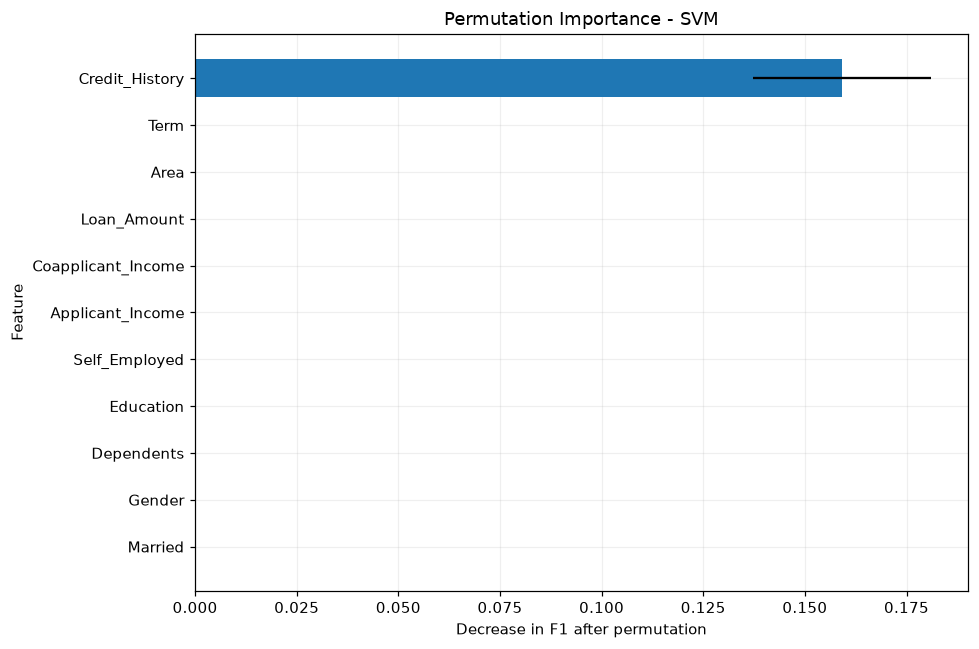

In [41]:
perm = permutation_importance(
    best_estimator,
    X_valid,
    y_valid,
    scoring="f1",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=N_JOBS,)

importance_table = pd.DataFrame({
    "Feature": X_valid.columns,
    "Importance_mean": perm.importances_mean,
    "Importance_std": perm.importances_std,
}).sort_values("Importance_mean", ascending=False)

display(importance_table)

plot_importance = importance_table.sort_values("Importance_mean", ascending=True)
plt.figure(figsize=(9, 6))
plt.barh(
    plot_importance["Feature"],
    plot_importance["Importance_mean"],
    xerr=plot_importance["Importance_std"],)
plt.xlabel("Decrease in F1 after permutation")
plt.ylabel("Feature")
plt.title(f"Permutation Importance - {best_model_name}")
plt.tight_layout()
plt.show()

importance_table.to_csv(OUTPUT_DIR / "permutation_importance.csv", index=False)

<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۱۰-۲. آماده‌سازی فضای عددی مدل برای تفسیر
</div>


In [42]:
feature_engineer_fitted = best_estimator.named_steps["feature_engineering"]
preprocessor_fitted = best_estimator.named_steps["preprocess"]
model_fitted = best_estimator.named_steps["model"]

X_train_engineered = feature_engineer_fitted.transform(X_train)
X_valid_engineered = feature_engineer_fitted.transform(X_valid)

X_train_transformed = np.asarray(preprocessor_fitted.transform(X_train_engineered), dtype=float)
X_valid_transformed = np.asarray(preprocessor_fitted.transform(X_valid_engineered), dtype=float)
transformed_feature_names = np.asarray(preprocessor_fitted.get_feature_names_out(), dtype=str)

assert X_train_transformed.shape[1] == len(transformed_feature_names)
assert X_valid_transformed.shape[1] == len(transformed_feature_names)

transformed_summary = pd.DataFrame({
    "Item": ["Training rows", "Validation rows", "Transformed features"],
    "Value": [X_train_transformed.shape[0], X_valid_transformed.shape[0], X_train_transformed.shape[1]],
})
display(transformed_summary)
print("نمونه نام ویژگی‌های تبدیل‌شده:")
print(transformed_feature_names[:20])


,Item,Value
0,Training rows,491
1,Validation rows,123
2,Transformed features,24


نمونه نام ویژگی‌های تبدیل‌شده:
['continuous__Applicant_Income' 'continuous__Coapplicant_Income'
 'continuous__Loan_Amount' 'continuous__Total_Income'
 'continuous__Loan_to_Income' 'continuous__Loan_Amount_per_Term'
 'discrete__Term' 'discrete__Credit_History' 'discrete__Has_Coapplicant'
 'categorical__Gender_Female' 'categorical__Gender_Male'
 'categorical__Married_No' 'categorical__Married_Yes'
 'categorical__Dependents_0' 'categorical__Dependents_1'
 'categorical__Dependents_2' 'categorical__Dependents_3+'
 'categorical__Education_Graduate' 'categorical__Education_Not Graduate'
 'categorical__Self_Employed_No']


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۱۰-۳. SHAP: تفسیر جهانی مدل
</div>


اهمیت SHAP تجمیع‌شده برحسب ویژگی اصلی:


,Raw_Feature,Mean_abs_SHAP,Mean_signed_SHAP
0,Credit_History,0.2168,-0.1828
1,Area,0.0168,-0.0032
2,Education,0.0160,0.0004
3,Dependents,0.0151,0.0019
4,Gender,0.0063,0.0037
5,Married,0.0060,-0.0037
6,Has_Coapplicant,0.0031,-0.0001
7,Self_Employed,0.0027,-0.0009
8,Coapplicant_Income,0.0017,-0.0000
9,Loan_Amount,0.0015,-0.0014


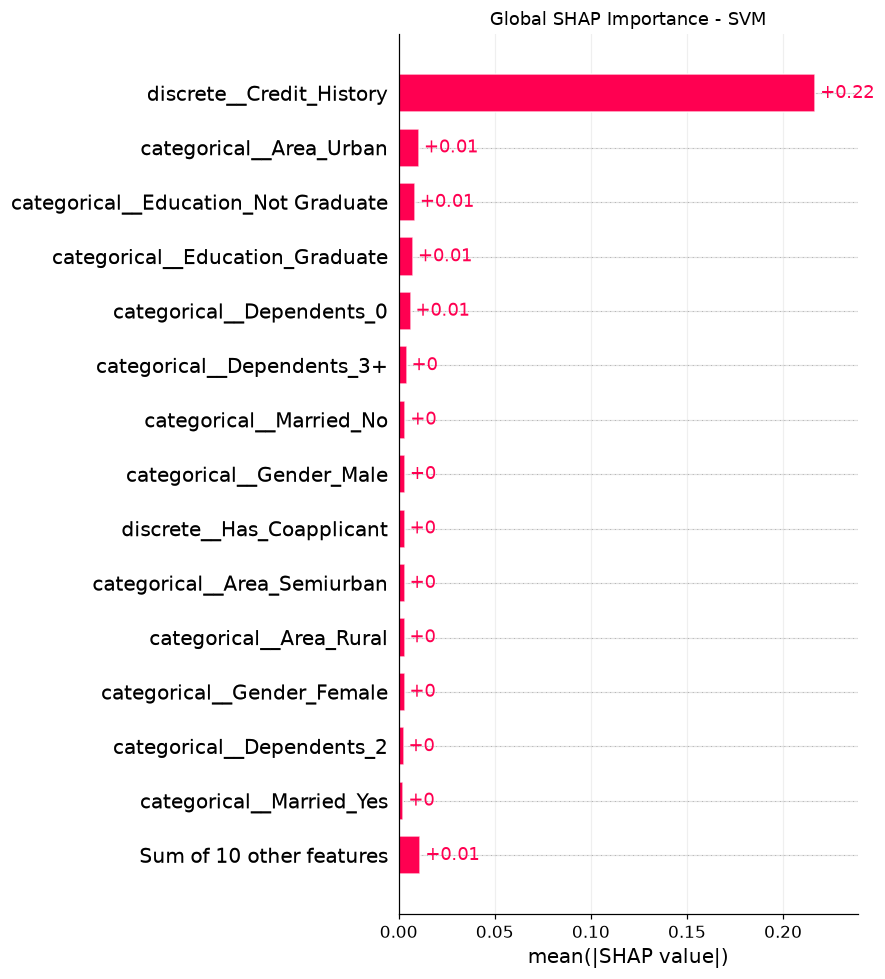

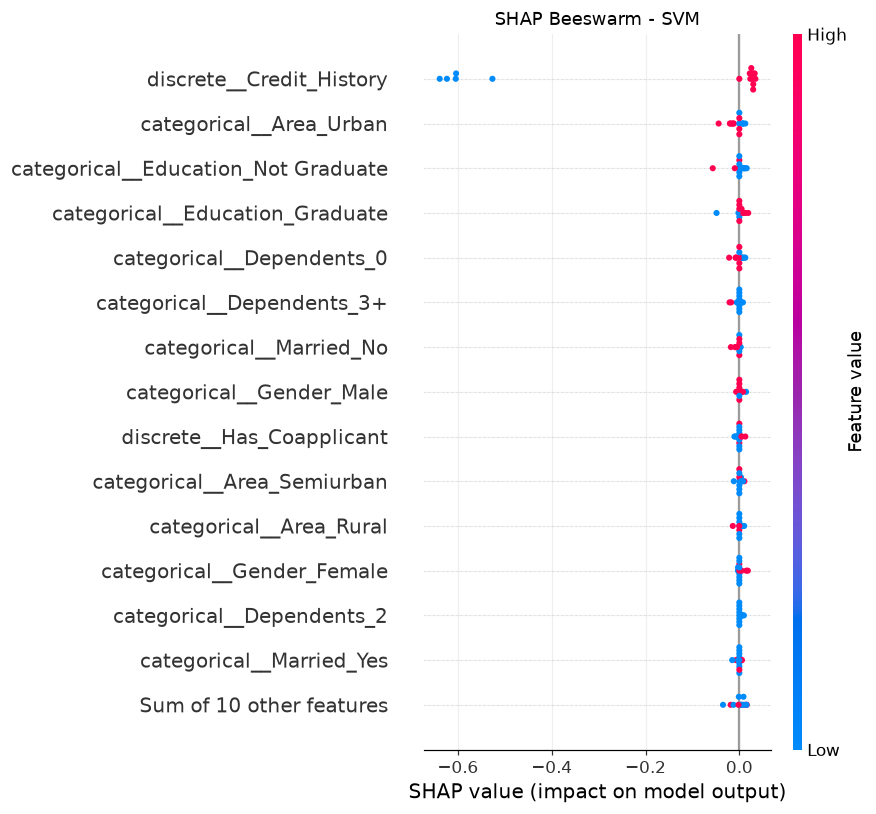

In [43]:
shap_global_completed = False
shap_explainer = None
shap_positive = None
X_shap_df = None
shap_importance_transformed = pd.DataFrame()
shap_importance_grouped = pd.DataFrame()

def positive_class_explanation(explanation):
    """خروجی SHAP را برای کلاس مثبت (تأیید وام) به شکل دوبعدی یکدست می‌کند."""
    values = np.asarray(explanation.values)
    base_values = np.asarray(explanation.base_values)
    data = np.asarray(explanation.data)

    if values.ndim == 3:
        values = values[:, :, 1]
        if base_values.ndim == 2:
            base_values = base_values[:, 1]
        elif base_values.ndim == 1 and base_values.size == 2:
            base_values = np.repeat(base_values[1], values.shape[0])
    elif base_values.ndim == 0:
        base_values = np.repeat(float(base_values), values.shape[0])

    return shap.Explanation(
        values=values,
        base_values=base_values,
        data=data,
        feature_names=list(transformed_feature_names),)

def raw_feature_group(transformed_name):
    """ویژگی‌های One-Hot را برای جدول نهایی به نام ویژگی اصلی برمی‌گرداند."""
    clean = transformed_name.split("__", 1)[-1]
    candidates = list(CONTINUOUS_FEATURES) + list(DISCRETE_NUMERIC_FEATURES) + list(CATEGORICAL_FEATURES)
    for raw_name in sorted(candidates, key=len, reverse=True):
        if clean == raw_name or clean.startswith(raw_name + "_"):
            return raw_name
    return clean

if SHAP_AVAILABLE:
    rng = np.random.default_rng(RANDOM_STATE)
    background_size = min(25, len(X_train_transformed))
    explain_size = min(15, len(X_valid_transformed))

    background_idx = rng.choice(len(X_train_transformed), size=background_size, replace=False)
    explain_idx = np.linspace(0, len(X_valid_transformed) - 1, explain_size, dtype=int)

    X_background = X_train_transformed[background_idx]
    X_shap_array = X_valid_transformed[explain_idx]
    X_shap_df = pd.DataFrame(X_shap_array, columns=transformed_feature_names)

    tree_models = (DecisionTreeClassifier, RandomForestClassifier, GradientBoostingClassifier)
    if isinstance(model_fitted, tree_models):
        shap_explainer = shap.Explainer(
            model_fitted, X_background, feature_names=list(transformed_feature_names)
        )
        shap_raw = shap_explainer(X_shap_array)
    elif isinstance(model_fitted, LogisticRegression):
        shap_explainer = shap.LinearExplainer(
            model_fitted, X_background, feature_names=list(transformed_feature_names)
        )
        shap_raw = shap_explainer(X_shap_array)
    else:
        def shap_predict_proba(array):
            return model_fitted.predict_proba(np.asarray(array, dtype=float))

        shap_explainer = shap.KernelExplainer(
            shap_predict_proba,
            X_background,
        )
        shap_values = shap_explainer.shap_values(
            X_shap_array,
            nsamples=60,
            silent=True,
        )

        shap_values_array = np.asarray(shap_values)
        if isinstance(shap_values, list):
            positive_values = np.asarray(shap_values[1])
        elif shap_values_array.ndim == 3:
            positive_values = shap_values_array[:, :, 1]
        else:
            positive_values = shap_values_array

        expected_value = np.asarray(shap_explainer.expected_value)
        positive_base = float(expected_value[1] if expected_value.size > 1 else expected_value.reshape(-1)[0])
        shap_positive = shap.Explanation(
            values=positive_values,
            base_values=np.repeat(positive_base, len(X_shap_array)),
            data=X_shap_array,
            feature_names=list(transformed_feature_names),
        )

    if not isinstance(model_fitted, SVC):
        shap_positive = positive_class_explanation(shap_raw)

    shap_importance_transformed = pd.DataFrame({
        "Feature": transformed_feature_names,
        "Mean_abs_SHAP": np.abs(shap_positive.values).mean(axis=0),
        "Mean_signed_SHAP": shap_positive.values.mean(axis=0),}).sort_values("Mean_abs_SHAP", ascending=False)
    shap_importance_transformed["Raw_Feature"] = shap_importance_transformed["Feature"].map(raw_feature_group)

    shap_importance_grouped = (
        shap_importance_transformed.groupby("Raw_Feature", as_index=False)
        .agg(Mean_abs_SHAP=("Mean_abs_SHAP", "sum"), Mean_signed_SHAP=("Mean_signed_SHAP", "sum"))
        .sort_values("Mean_abs_SHAP", ascending=False)
        .reset_index(drop=True))

    print("اهمیت SHAP تجمیع‌شده برحسب ویژگی اصلی:")
    display(shap_importance_grouped)

    shap.plots.bar(shap_positive, max_display=15, show=False)
    plt.title(f"Global SHAP Importance - {best_model_name}")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "shap_global_bar.png", dpi=300, bbox_inches="tight")
    plt.show()

    shap.plots.beeswarm(shap_positive, max_display=15, show=False)
    plt.title(f"SHAP Beeswarm - {best_model_name}")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "shap_beeswarm.png", dpi=300, bbox_inches="tight")
    plt.show()

    shap_importance_transformed.to_csv(OUTPUT_DIR / "shap_importance_transformed.csv", index=False)
    shap_importance_grouped.to_csv(OUTPUT_DIR / "shap_importance_grouped.csv", index=False)
    shap_global_completed = True
else:
    print("SHAP در این محیط نصب نیست. نوت‌بوک بدون خطا ادامه می‌یابد.")

<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۱۰-۴. SHAP: توضیح محلی تصمیم‌های درست و خطاها

,Case_Label,Actual,Predicted,Approval_Probability,Error_Type
150,Correct high-confidence,N,N,0.0863,Correct
216,False Positive,N,Y,0.8201,False Positive
326,False Negative,Y,N,0.0889,False Negative


توضیح SHAP محلی: Correct high-confidence


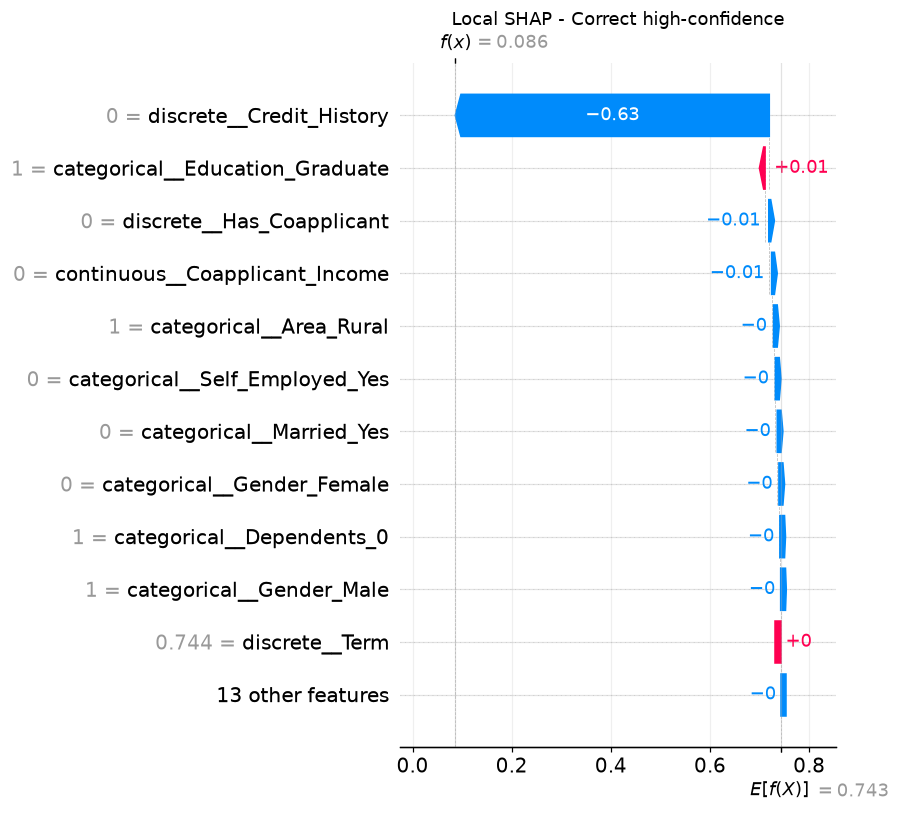

توضیح SHAP محلی: False Positive


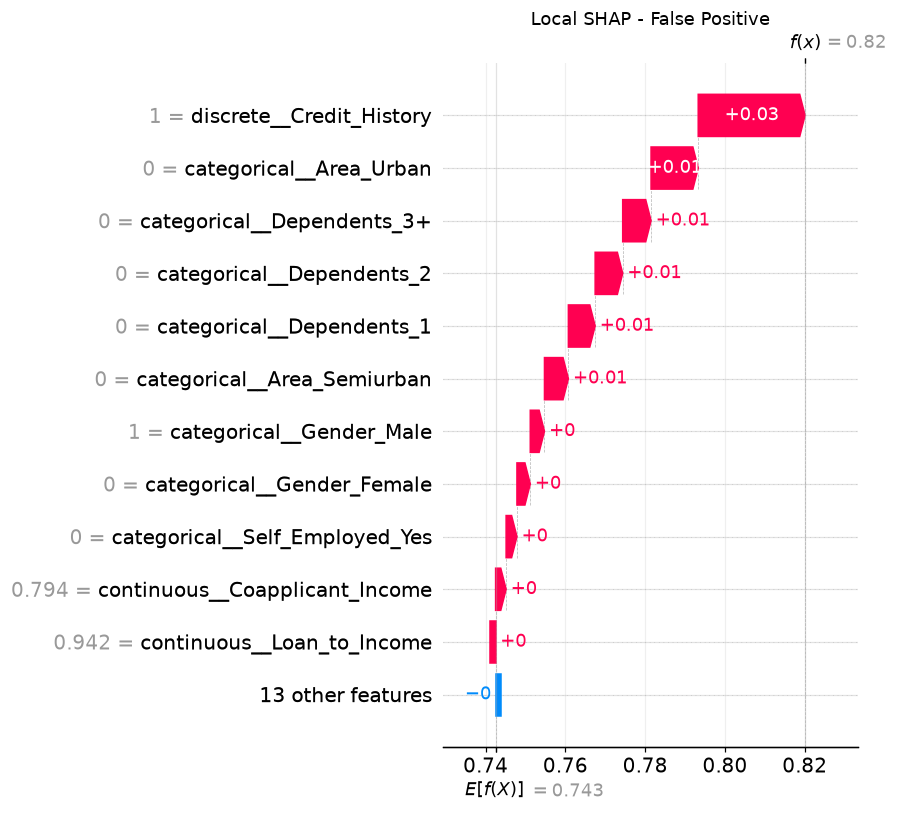

توضیح SHAP محلی: False Negative


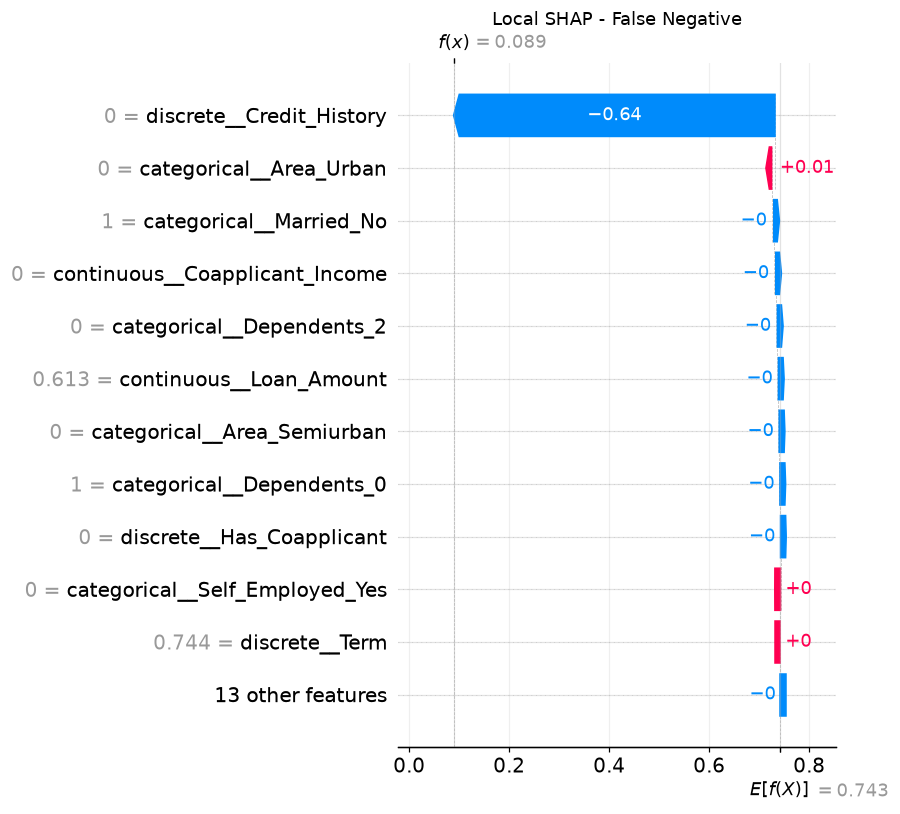

In [44]:
shap_local_completed = False
local_case_indices = []
local_case_labels = []

# یک نمونه صحیح با اطمینان بالا
correct_cases = error_analysis[error_analysis["Error_Type"] == "Correct"].copy()
if not correct_cases.empty:
    correct_cases["Confidence"] = np.where(
        correct_cases["Predicted"] == "Y",
        correct_cases["Approval_Probability"],
        1 - correct_cases["Approval_Probability"],
    )
    local_case_indices.append(correct_cases["Confidence"].idxmax())
    local_case_labels.append("Correct high-confidence")

for error_type in ["False Positive", "False Negative"]:
    subset = error_analysis[error_analysis["Error_Type"] == error_type]
    if not subset.empty:
        if error_type == "False Positive":
            idx = subset["Approval_Probability"].idxmax()
        else:
            idx = subset["Approval_Probability"].idxmin()
        local_case_indices.append(idx)
        local_case_labels.append(error_type)

local_case_table = error_analysis.loc[local_case_indices, [
    "Actual", "Predicted", "Approval_Probability", "Error_Type"
]].copy()
local_case_table.insert(0, "Case_Label", local_case_labels)
display(local_case_table)

if SHAP_AVAILABLE and shap_explainer is not None and local_case_indices:
    local_raw = X_valid.loc[local_case_indices]
    local_engineered = feature_engineer_fitted.transform(local_raw)
    local_transformed = np.asarray(preprocessor_fitted.transform(local_engineered), dtype=float)
    if isinstance(model_fitted, SVC):
        local_values = shap_explainer.shap_values(
            local_transformed,
            nsamples=80,
            silent=True,
        )
        local_values_array = np.asarray(local_values)
        if isinstance(local_values, list):
            local_positive_values = np.asarray(local_values[1])
        elif local_values_array.ndim == 3:
            local_positive_values = local_values_array[:, :, 1]
        else:
            local_positive_values = local_values_array

        expected_value = np.asarray(shap_explainer.expected_value)
        local_base = float(expected_value[1] if expected_value.size > 1 else expected_value.reshape(-1)[0])
        local_positive = shap.Explanation(
            values=local_positive_values,
            base_values=np.repeat(local_base, len(local_transformed)),
            data=local_transformed,
            feature_names=list(transformed_feature_names),
        )
    else:
        local_raw_explanation = shap_explainer(local_transformed)
        local_positive = positive_class_explanation(local_raw_explanation)

    for position, case_label in enumerate(local_case_labels):
        print(f"توضیح SHAP محلی: {case_label}")
        shap.plots.waterfall(local_positive[position], max_display=12, show=False)
        plt.title(f"Local SHAP - {case_label}")
        plt.tight_layout()
        safe_label = case_label.lower().replace(" ", "_")
        plt.savefig(OUTPUT_DIR / f"shap_local_{safe_label}.png", dpi=300, bbox_inches="tight")
        plt.show()
    shap_local_completed = True

<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۱۰-۵. LIME: مدل جانشین محلی
</div>


LIME-style explanation: Correct high-confidence | Local R²=0.771


,Feature,Local_Coefficient,Absolute_Contribution
7,discrete__Credit_History,-0.5741,0.5741
12,categorical__Married_Yes,-0.0111,0.0111
18,categorical__Education_Not Graduate,0.0104,0.0104
1,continuous__Coapplicant_Income,-0.0104,0.0104
10,categorical__Gender_Male,0.0098,0.0098
13,categorical__Dependents_0,-0.0096,0.0096
17,categorical__Education_Graduate,-0.0075,0.0075
16,categorical__Dependents_3+,-0.0055,0.0055
8,discrete__Has_Coapplicant,-0.0051,0.0051
19,categorical__Self_Employed_No,-0.0051,0.0051


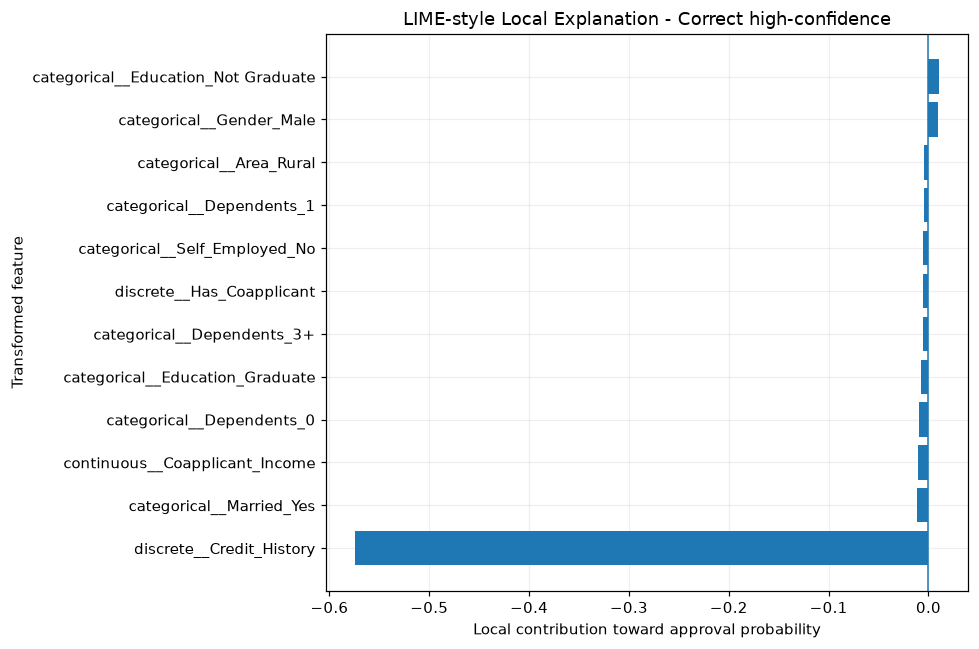

LIME-style explanation: False Positive | Local R²=0.100


,Feature,Local_Coefficient,Absolute_Contribution
7,discrete__Credit_History,0.1045,0.1045
23,categorical__Area_Urban,0.0126,0.0126
17,categorical__Education_Graduate,0.0105,0.0105
4,continuous__Loan_to_Income,-0.0102,0.0102
16,categorical__Dependents_3+,0.0099,0.0099
14,categorical__Dependents_1,0.0084,0.0084
1,continuous__Coapplicant_Income,-0.0084,0.0084
8,discrete__Has_Coapplicant,-0.0078,0.0078
20,categorical__Self_Employed_Yes,-0.0068,0.0068
10,categorical__Gender_Male,0.0067,0.0067


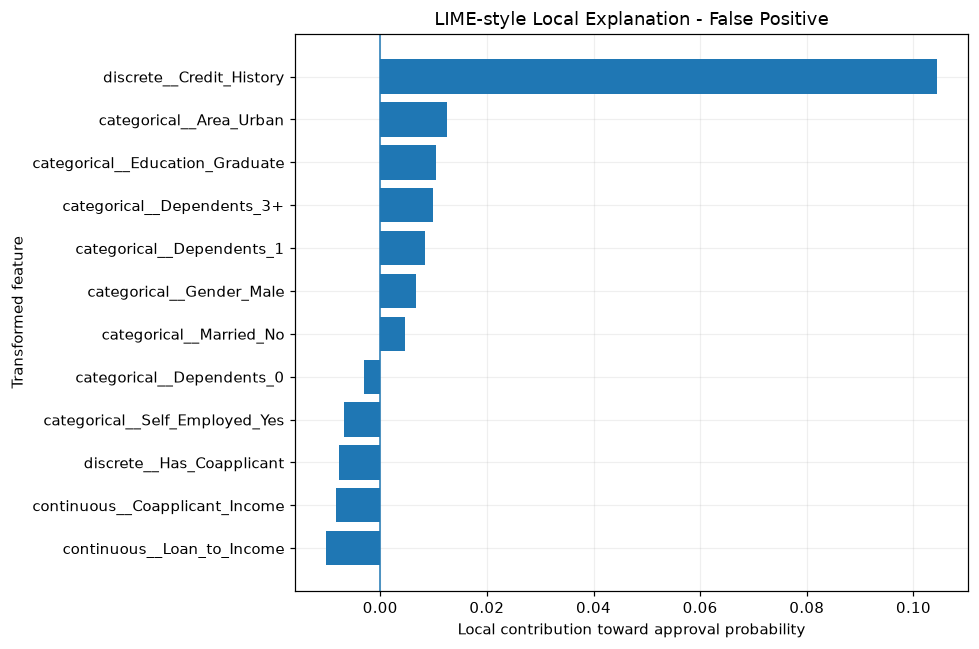

LIME-style explanation: False Negative | Local R²=0.757


,Feature,Local_Coefficient,Absolute_Contribution
7,discrete__Credit_History,-0.5677,0.5677
9,categorical__Gender_Female,-0.0167,0.0167
5,continuous__Loan_Amount_per_Term,-0.0128,0.0128
16,categorical__Dependents_3+,-0.0124,0.0124
12,categorical__Married_Yes,0.0118,0.0118
10,categorical__Gender_Male,-0.0082,0.0082
1,continuous__Coapplicant_Income,-0.0079,0.0079
17,categorical__Education_Graduate,-0.0068,0.0068
4,continuous__Loan_to_Income,-0.0063,0.0063
0,continuous__Applicant_Income,-0.0059,0.0059


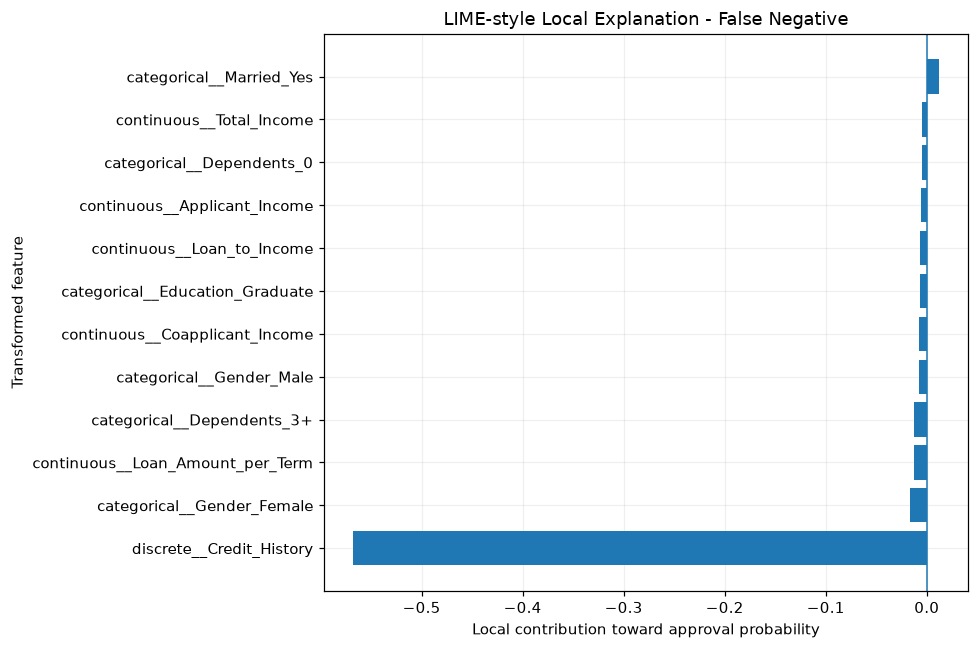

,Case_Label,Original_Model_Probability,Local_Surrogate_Probability,Weighted_Local_R2
0,Correct high-confidence,0.0863,0.0877,0.7712
1,False Positive,0.8201,0.7973,0.1003
2,False Negative,0.0889,0.0780,0.7566


In [45]:
def lime_style_explanation(
    model,
    x_instance,
    training_matrix,
    feature_names,
    n_samples=2000,
    random_state=42,):

    rng = np.random.default_rng(random_state)
    x_instance = np.asarray(x_instance, dtype=float).reshape(-1)
    n_features = len(x_instance)

    donor_idx = rng.integers(0, len(training_matrix), size=n_samples)
    donors = training_matrix[donor_idx]
    masks = rng.integers(0, 2, size=(n_samples, n_features)).astype(float)
    masks[0, :] = 1.0

    perturbed = np.where(masks == 1.0, x_instance, donors)
    probabilities = model.predict_proba(perturbed)[:, 1]

    distances = pairwise_distances(masks, np.ones((1, n_features)), metric="euclidean").ravel()
    kernel_width = max(np.sqrt(n_features) * 0.75, 1.0)
    weights = np.exp(-(distances ** 2) / (kernel_width ** 2))

    surrogate = Ridge(alpha=1.0)
    surrogate.fit(masks, probabilities, sample_weight=weights)
    fidelity = surrogate.score(masks, probabilities, sample_weight=weights)

    explanation = pd.DataFrame({
        "Feature": feature_names,
        "Local_Coefficient": surrogate.coef_,
        "Absolute_Contribution": np.abs(surrogate.coef_),
    }).sort_values("Absolute_Contribution", ascending=False)

    return explanation, float(fidelity), float(surrogate.predict(np.ones((1, n_features)))[0])

lime_style_completed = False
lime_summary_rows = []

if local_case_indices:
    local_raw = X_valid.loc[local_case_indices]
    local_engineered = feature_engineer_fitted.transform(local_raw)
    local_transformed = np.asarray(preprocessor_fitted.transform(local_engineered), dtype=float)

    for pos, (case_idx, case_label) in enumerate(zip(local_case_indices, local_case_labels)):
        explanation, fidelity, local_surrogate_probability = lime_style_explanation(
            model=model_fitted,
            x_instance=local_transformed[pos],
            training_matrix=X_train_transformed,
            feature_names=transformed_feature_names,
            n_samples=2000,
            random_state=RANDOM_STATE + pos,)

        original_probability = float(model_fitted.predict_proba(local_transformed[[pos]])[:, 1][0])
        lime_summary_rows.append({
            "Case_Label": case_label,
            "Original_Model_Probability": original_probability,
            "Local_Surrogate_Probability": local_surrogate_probability,
            "Weighted_Local_R2": fidelity,})

        top = explanation.head(12).sort_values("Local_Coefficient")
        print(f"LIME-style explanation: {case_label} | Local R²={fidelity:.3f}")
        display(explanation.head(12))

        plt.figure(figsize=(9, 6))
        plt.barh(top["Feature"], top["Local_Coefficient"])
        plt.axvline(0, linewidth=1)
        plt.xlabel("Local contribution toward approval probability")
        plt.ylabel("Transformed feature")
        plt.title(f"LIME-style Local Explanation - {case_label}")
        plt.tight_layout()
        safe_label = case_label.lower().replace(" ", "_")
        plt.savefig(OUTPUT_DIR / f"lime_style_{safe_label}.png", dpi=300, bbox_inches="tight")
        plt.show()

    lime_summary = pd.DataFrame(lime_summary_rows)
    display(lime_summary)
    lime_summary.to_csv(OUTPUT_DIR / "lime_style_summary.csv", index=False)
    lime_style_completed = True
else:
    lime_summary = pd.DataFrame()

<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۱۰-۶. Partial Dependence: جهت اثر ویژگی‌های مهم
</div>


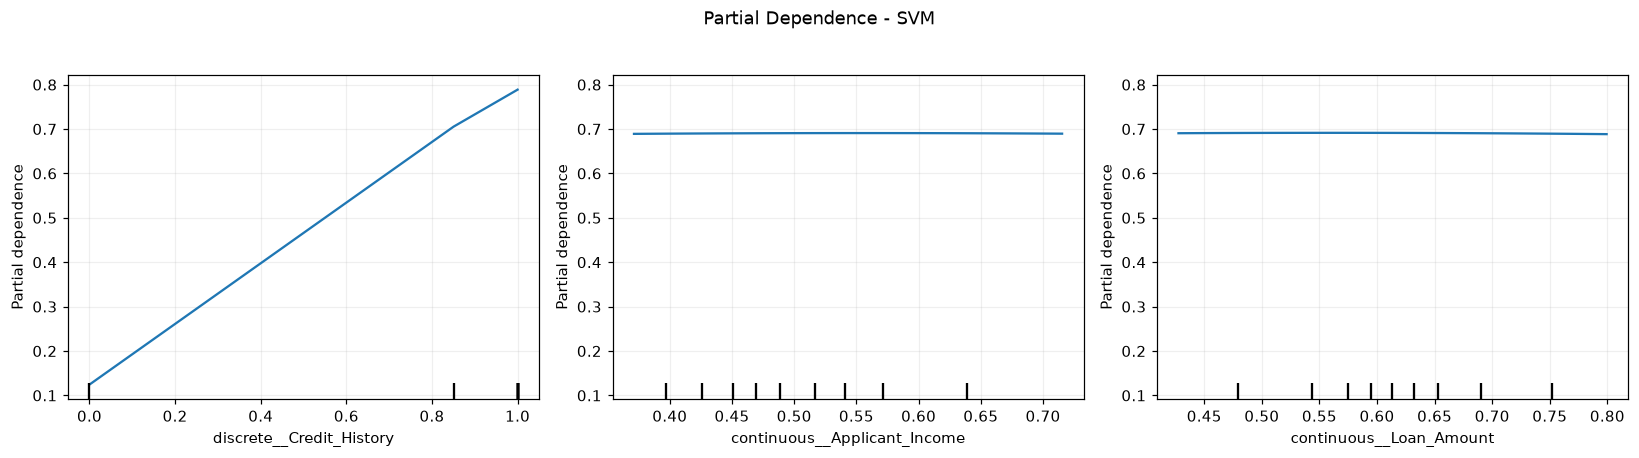

In [46]:
pdp_completed = False
preferred_tokens = ["Credit_History", "Applicant_Income", "Loan_Amount"]
pdp_indices = []
pdp_labels = []

for token in preferred_tokens:
    matches = [i for i, name in enumerate(transformed_feature_names) if name.endswith("__" + token)]
    if matches:
        pdp_indices.append(matches[0])
        pdp_labels.append(transformed_feature_names[matches[0]])

if pdp_indices:
    fig, axes = plt.subplots(1, len(pdp_indices), figsize=(5 * len(pdp_indices), 4))
    if len(pdp_indices) == 1:
        axes = [axes]
    PartialDependenceDisplay.from_estimator(
        model_fitted,
        X_train_transformed,
        features=pdp_indices,
        feature_names=list(transformed_feature_names),
        kind="average",
        ax=axes,)
    fig.suptitle(f"Partial Dependence - {best_model_name}", y=1.03)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "partial_dependence.png", dpi=300, bbox_inches="tight")
    plt.show()
    pdp_completed = True
else:
    print("ویژگی‌های انتخاب‌شده برای PDP در فضای تبدیل‌شده پیدا نشدند.")

<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۱۰-۷. مقایسه و همگرایی روش‌های تفسیرپذیری
</div>


In [47]:
interpretability_comparison = importance_table[["Feature", "Importance_mean"]].copy()
interpretability_comparison = interpretability_comparison.rename(columns={
    "Feature": "Raw_Feature",
    "Importance_mean": "Permutation_F1_Decrease",
})

if not shap_importance_grouped.empty:
    interpretability_comparison = interpretability_comparison.merge(
        shap_importance_grouped[["Raw_Feature", "Mean_abs_SHAP"]],
        on="Raw_Feature",
        how="outer",
    ).fillna(0)
    interpretability_comparison["Permutation_Rank"] = (
        interpretability_comparison["Permutation_F1_Decrease"].rank(ascending=False, method="min")
    )
    interpretability_comparison["SHAP_Rank"] = (
        interpretability_comparison["Mean_abs_SHAP"].rank(ascending=False, method="min")
    )
    interpretability_comparison["Average_Rank"] = (
        interpretability_comparison[["Permutation_Rank", "SHAP_Rank"]].mean(axis=1)
    )
    interpretability_comparison = interpretability_comparison.sort_values("Average_Rank")
else:
    interpretability_comparison["Permutation_Rank"] = (
        interpretability_comparison["Permutation_F1_Decrease"].rank(ascending=False, method="min")
    )
    interpretability_comparison = interpretability_comparison.sort_values("Permutation_Rank")

display(interpretability_comparison)
interpretability_comparison.to_csv(
    OUTPUT_DIR / "interpretability_method_comparison.csv", index=False
)


,Raw_Feature,Permutation_F1_Decrease,Mean_abs_SHAP,Permutation_Rank,SHAP_Rank,Average_Rank
3,Credit_History,0.1591,0.2168,1.0000,1.0000,1.0000
1,Area,0.0000,0.0168,2.0000,2.0000,2.0000
5,Education,0.0000,0.0160,2.0000,3.0000,2.5000
4,Dependents,0.0000,0.0151,2.0000,4.0000,3.0000
6,Gender,0.0000,0.0063,2.0000,5.0000,3.5000
11,Married,0.0000,0.0060,2.0000,6.0000,4.0000
7,Has_Coapplicant,0.0000,0.0031,2.0000,7.0000,4.5000
12,Self_Employed,0.0000,0.0027,2.0000,8.0000,5.0000
2,Coapplicant_Income,0.0000,0.0017,2.0000,9.0000,5.5000
8,Loan_Amount,0.0000,0.0015,2.0000,10.0000,6.0000


<div style="background:#D9E4DE;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

# ۱۱. بررسی بیش‌برازش یا کم‌برازش با منحنی یادگیری
</div>


,Training samples,Train F1 mean,Train F1 std,Validation F1 mean,Validation F1 std
0,130,0.8905,0.0096,0.8569,0.0061
1,196,0.8733,0.0025,0.8677,0.0069
2,261,0.8718,0.0113,0.8700,0.0102
3,327,0.8709,0.0058,0.8700,0.0102


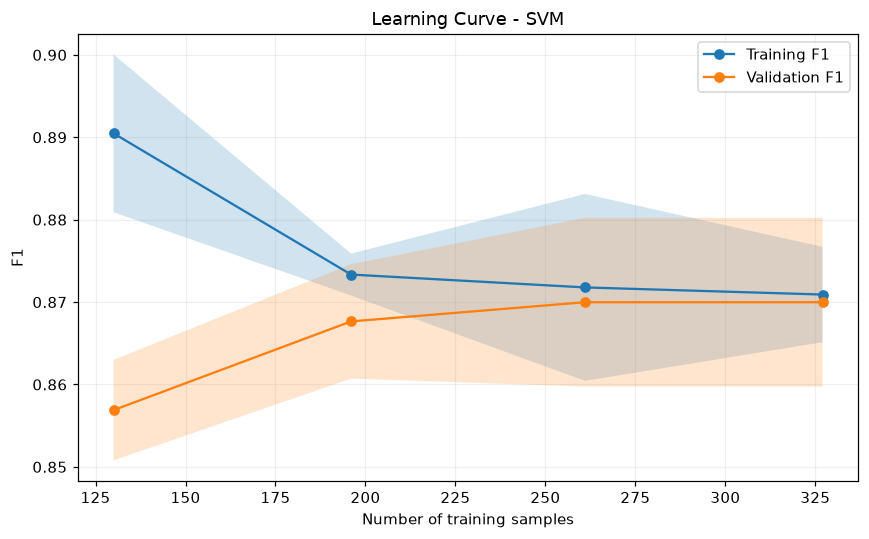

In [48]:
train_sizes, train_scores, validation_scores = learning_curve(
    clone(best_estimator),
    X_train,
    y_train,
    cv=CV,
    scoring="f1",
    train_sizes=np.linspace(0.40, 1.00, 4),
    n_jobs=1,
    shuffle=True,
    random_state=RANDOM_STATE,)

learning_table = pd.DataFrame({
    "Training samples": train_sizes,
    "Train F1 mean": train_scores.mean(axis=1),
    "Train F1 std": train_scores.std(axis=1),
    "Validation F1 mean": validation_scores.mean(axis=1),
    "Validation F1 std": validation_scores.std(axis=1),})
display(learning_table)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_scores.mean(axis=1), marker="o", label="Training F1")
plt.plot(train_sizes, validation_scores.mean(axis=1), marker="o", label="Validation F1")
plt.fill_between(
    train_sizes,
    train_scores.mean(axis=1) - train_scores.std(axis=1),
    train_scores.mean(axis=1) + train_scores.std(axis=1),
    alpha=0.2,)
plt.fill_between(
    train_sizes,
    validation_scores.mean(axis=1) - validation_scores.std(axis=1),
    validation_scores.mean(axis=1) + validation_scores.std(axis=1),
    alpha=0.2,)
plt.xlabel("Number of training samples")
plt.ylabel("F1")
plt.title(f"Learning Curve - {best_model_name}")
plt.legend()
plt.tight_layout()
plt.show()

<div style="background:#D9E4DE;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

# ۱۲. تحلیل عملکرد در زیرگروه‌ها
</div>


In [49]:
def subgroup_metrics(feature):
    rows = []
    groups = X_valid[feature].fillna("Missing")
    for group in groups.unique():
        mask = groups == group
        if mask.sum() < 10:
            continue
        true_group = y_valid.loc[mask]
        pred_group = pd.Series(valid_pred_optimized, index=X_valid.index).loc[mask]
        rows.append({
            "Feature": feature,
            "Group": group,
            "N": int(mask.sum()),
            "Accuracy": accuracy_score(true_group, pred_group),
            "Balanced_Accuracy": balanced_accuracy_score(true_group, pred_group),
            "Precision": precision_score(true_group, pred_group, zero_division=0),
            "Recall": recall_score(true_group, pred_group, zero_division=0),
            "F1": f1_score(true_group, pred_group, zero_division=0),})
    return pd.DataFrame(rows)

subgroup_table = pd.concat([
    subgroup_metrics("Gender"),
    subgroup_metrics("Area"),
    subgroup_metrics("Education"),
], ignore_index=True)

display(subgroup_table)

,Feature,Group,N,Accuracy,Balanced_Accuracy,Precision,Recall,F1
0,Gender,Male,96,0.8542,0.7549,0.8500,0.9714,0.9067
1,Gender,Female,25,0.8400,0.8182,0.7778,1.0000,0.8750
2,Area,Rural,34,0.6765,0.5606,0.6774,0.9545,0.7925
3,Area,Semiurban,49,0.9592,0.9231,0.9474,1.0000,0.9730
4,Area,Urban,40,0.8500,0.7892,0.8387,0.9630,0.8966
5,Education,Graduate,100,0.8500,0.7516,0.8333,0.9859,0.9032
6,Education,Not Graduate,23,0.8261,0.7976,0.8125,0.9286,0.8667


<div style="background:#D9E4DE;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

# ۱۳. آموزش نهایی و پیش‌بینی مجموعه آزمون
</div>


In [50]:
final_estimator = clone(best_estimator)

full_oof_probabilities = cross_val_predict(
    clone(final_estimator),
    X,
    y,
    cv=CV,
    method="predict_proba",
    n_jobs=N_JOBS,
)[:, 1]

final_threshold, full_threshold_table = find_best_threshold(
    y,
    full_oof_probabilities,
    metric="f1",
)

final_estimator.fit(X, y)
external_probabilities = probability_scores(final_estimator, X_external_test)
external_predictions_binary = (external_probabilities >= final_threshold).astype(int)
external_predictions_label = np.where(external_predictions_binary == 1, "Y", "N")

submission = pd.DataFrame({"Status": external_predictions_label})
detailed_predictions = pd.DataFrame({
    "Row_ID": np.arange(1, len(X_external_test) + 1),
    "Approval_Probability": external_probabilities,
    "Predicted_Status": external_predictions_label,
})

submission_path = OUTPUT_DIR / "loan_test_predictions.csv"
detailed_path = OUTPUT_DIR / "loan_test_predictions_with_probability.csv"
model_path = OUTPUT_DIR / "best_loan_model.joblib"
comparison_path = OUTPUT_DIR / "model_comparison_results.csv"
params_path = OUTPUT_DIR / "best_model_parameters.json"
preprocessing_path = OUTPUT_DIR / "preprocessing_comparisons.xlsx"

submission.to_csv(submission_path, index=False)
detailed_predictions.to_csv(detailed_path, index=False)
joblib.dump({
    "estimator": final_estimator,
    "threshold": final_threshold,
    "target_mapping": {"N": 0, "Y": 1},
}, model_path)
tuned_results.to_csv(comparison_path, index=False)

with open(params_path, "w", encoding="utf-8") as file:
    json.dump(
        {
            "best_model": best_model_name,
            "best_parameters": {k: str(v) for k, v in best_params[best_model_name].items()},
            "final_threshold": final_threshold,
            "preprocessing": preprocessing_decisions.to_dict(orient="records"),
        },
        file,
        ensure_ascii=False,
        indent=2,
    )

with pd.ExcelWriter(preprocessing_path) as writer:
    imputation_results.to_excel(writer, sheet_name="Imputation", index=False)
    scaling_results.to_excel(writer, sheet_name="Scaling", index=False)
    outlier_results.to_excel(writer, sheet_name="Outlier_Skew", index=False)
    imbalance_results.to_excel(writer, sheet_name="Imbalance", index=False)

print(f"مدل نهایی: {best_model_name}")
print(f"آستانه نهایی OOF: {final_threshold:.3f}")
print(f"تعداد پیش‌بینی‌ها: {len(submission)}")
print("توزیع پیش‌بینی نهایی:")
display(submission["Status"].value_counts().to_frame("Count"))

print("فایل‌های ذخیره‌شده:")
for path in [submission_path, detailed_path, model_path, comparison_path, params_path, preprocessing_path]:
    print(path.resolve())

مدل نهایی: SVM
آستانه نهایی OOF: 0.265
تعداد پیش‌بینی‌ها: 367
توزیع پیش‌بینی نهایی:


,Count
Status,
Y,308
N,59


فایل‌های ذخیره‌شده:
C:\Users\Sarir\Downloads\outputs_complete\loan_test_predictions.csv
C:\Users\Sarir\Downloads\outputs_complete\loan_test_predictions_with_probability.csv
C:\Users\Sarir\Downloads\outputs_complete\best_loan_model.joblib
C:\Users\Sarir\Downloads\outputs_complete\model_comparison_results.csv
C:\Users\Sarir\Downloads\outputs_complete\best_model_parameters.json
C:\Users\Sarir\Downloads\outputs_complete\preprocessing_comparisons.xlsx


<div style="background:#FFF6F6;text-align: right; padding:15px; border-radius:8px; border:1px solid #ccc; line-height:1.9;direction:rtl ; font-size:15px;">

## ۱۳-۱. کنترل صحت خروجی نهایی
</div>


In [51]:
assert len(submission) == len(test_raw), "تعداد پیش‌بینی‌ها با تعداد ردیف‌های آزمون برابر نیست."
assert submission["Status"].isna().sum() == 0, "خروجی دارای مقدار گمشده است."
assert set(submission["Status"].unique()).issubset({"Y", "N"}), "برچسب خروجی نامعتبر است."
assert detailed_predictions["Approval_Probability"].between(0, 1).all(), "احتمال‌ها خارج از بازه صفر و یک‌اند."

display(submission.head(10))

,Status
0,Y
1,Y
2,Y
3,Y
4,Y
5,Y
6,Y
7,N
8,Y
9,Y
